# Stage 2: Bivariate analysis (two variables at a time)

**Status (2026-10-28):** Stage 2 has begun, at the owner's word (A14). Sections 1 (the `rights` lens, B1 to B19)
and 2 (`firms`, B20 to B26) are done; the other lenses follow in Stage 1's order, one section at a time. The method
is in ADR 0030. The evidence atlas (the website) is updated only once Stage 2 is finished, at the owner's instruction.

**Purpose.** Test how pairs of variables relate: whether they move together, in what shape, how strongly, and for
whom. This turns Stage 1's descriptions into early signals, and sorts the signals worth carrying into Stage 3 from
the ones that are mechanics of the IP system, quirks of the records, or chance.

**Two cautions.** With hundreds of thousands of rows almost any difference is "statistically significant", so the
size of an association matters more than its p-value, and every finding here leads with a size and an interval. And
two things moving together does not mean one causes the other: a third factor (the applicant's origin, the
technology, the period) often drives both. Each lead names its candidate third factors; Stage 3 tests them.

## How to read this notebook

- **Every observation is evidenced.** Observations are numbered (**B1**, **B2**, ...) and quote the numbers from the
  output cells directly above them. If a number is not on the page, it is not a finding.
- **Each observation is labelled with its strength of evidence**, as the research goal requires: *descriptive* (what
  the data shows), *observational* (an association that may have other explanations), *causal* (an effect, which needs
  a design this EDA does not have) or *projected* (an estimate of the future). Nearly everything in Stage 2 is
  observational.
- **Plain English first.** Technical terms are explained where they first appear and in
  [`GLOSSARY.md`](../../GLOSSARY.md).
- **Every chart names its source** underneath it.
- **Unit of analysis.** Each section works on one *lens*, a table with one row per thing being described, defined in
  [`analysis/eda/build.py`](../eda/build.py) and described column by column in
  [`analysis/eda/variables.yaml`](../eda/variables.yaml). Stage 1 (`01_univariate.ipynb`) profiled every column; its
  rules for using each one (`docs/stage-1-summary.md`, section 6) apply here.

## How each lens is worked through

Each lens section has two parts.

**1. The screen: every pair.** Every pair of the lens's variables is measured on one scale, its **strength**, from 0
(no association) to 1 (one variable fully determines the other), whatever the kinds of variable:

| Pair | Measure | What it says |
|---|---|---|
| two numbers | Spearman's rho (its size) | whether the two rise or fall together, in any shape, from their ranks |
| a number and a category | the rank correlation ratio | how much of the number's spread (in ranks) the categories account for |
| two categories | Cramér's V (corrected for many categories) | how far the categories go together beyond chance |

For two yes/no variables, or a yes/no and a number, the three measures give the same value, so the scale is shared.
By convention 0.1 is a small association, 0.3 a moderate one and 0.5 a strong one. Which columns are screened, and
why the others are not (identifiers, and dates whose content is in another column), is set in
[`analysis/eda/screens.yaml`](../eda/screens.yaml); a test checks that it names every column of the lens.

A pair becomes a **lead** only if it passes four tests:
1. its strength is at least 0.1 in the **discovery sample**;
2. it survives the **correction for the number of pairs tested** (the Benjamini-Hochberg false discovery rate below
   5%), because among hundreds of pairs some pass by chance;
3. it holds again, at 0.1 or more and in the same direction, in a **replication sample** that played no part in finding
   it (a second period, or the other random half of the lens);
4. it is not **by construction**: two versions of one measure, or a total and its parts, are screened but never
   counted as leads (`screens.yaml` lists them).

Leads that are versions of one finding (the origin of the filer and of the current holder, say) are reported once,
with the strongest version. Each lead gets a 95% **bootstrap interval** for its strength, its direction in words and
its **candidate third factors**: other variables tied to both members by at least 0.1.

**2. The planned pairs.** Stage 1 named the pairs worth a proper look (`docs/stage-1-summary.md`, section 7). Each is
measured in the units that mean something (a difference in grant rates in percentage points, a median in years),
with a 95% interval, in two periods, and with its third factors named.

A lead is a signal for Stage 3 to test, not a conclusion.

## Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from eda import bivariate as bi
from eda import sql, style
from eda import univariate as uni

style.setup()
pd.set_option("display.max_colwidth", 90)

## 1. Lens: IP rights (one row per right)

**Rules carried from Stage 1** (`docs/stage-1-summary.md`, section 6): rights are always compared within one type,
with standard patents, provisionals and second-tier patents apart; "who files" is the founding applicant
(`founding_australian`, `founder_type`); grant rates and times only for decided years; representation is
`representation` (an attorney is an agent of five or more applicants); lifetimes come from survival curves with
rights still in force kept as unfinished; trade mark expedite shares only on one side of November 2018; gender
estimates only for inventors in Australia.

**The two samples.** The screen's discovery sample is rights filed FY2010 to FY2019, old enough for most to be decided;
the replication sample is rights filed FY2000 to FY2009. A pair that holds in both periods is not an accident of one
decade. Each type of right is screened on its own, up to 200,000 rights per sample (a fixed pseudo-random selection),
because pooling types would mostly show that patents differ from trade marks.

### 1.0 The screen: every pair, within each type of right

In [2]:
RIGHT_TYPES = {
    "standard": "Standard patents",
    "trade_mark": "Trade marks",
    "design": "Designs",
    "provisional": "Provisional applications",
    "second_tier": "Second-tier patents",
    "pbr": "Plant breeder's rights",
}
GROUPS = bi.screens()["rights"]["groups"]


def lab(c):
    return bi.screen_label("rights", c)


rights_screen = {t: bi.run_screen("rights", t) for t in RIGHT_TYPES}
rights_leads = {t: bi.distinct_leads(s["verdicts"], GROUPS) for t, s in rights_screen.items()}
screen_summary = pd.DataFrame(
    {
        RIGHT_TYPES[t]: {
            "variables measured": len(
                set(s["discovery"].dropna(subset=["strength"])[["variable 1", "variable 2"]].to_numpy().ravel())
            ),
            "rows (discovery)": s["n"][0],
            "rows (replication)": s["n"][1],
            **bi.verdict_counts(s["verdicts"]).to_dict(),
            "distinct leads": len(rights_leads[t]),
        }
        for t, s in rights_screen.items()
    }
).T
display(screen_summary)
print("Distinct leads, all types:", sum(len(d) for d in rights_leads.values()))

,variables measured,rows (discovery),rows (replication),lead,not replicated,negligible,not significant,by construction,too few rows,distinct leads
Standard patents,53,200000,200000,490,85,683,0,113,582,59
Trade marks,43,200000,200000,304,22,465,0,105,1057,45
Designs,39,68339,51137,271,68,299,0,92,1223,33
Provisional applications,23,53540,71549,41,7,154,0,50,1701,9
Second-tier patents,51,18629,10368,436,158,566,0,108,685,63
Plant breeder's rights,27,3451,3607,107,29,130,0,64,1623,14


Distinct leads, all types: 223


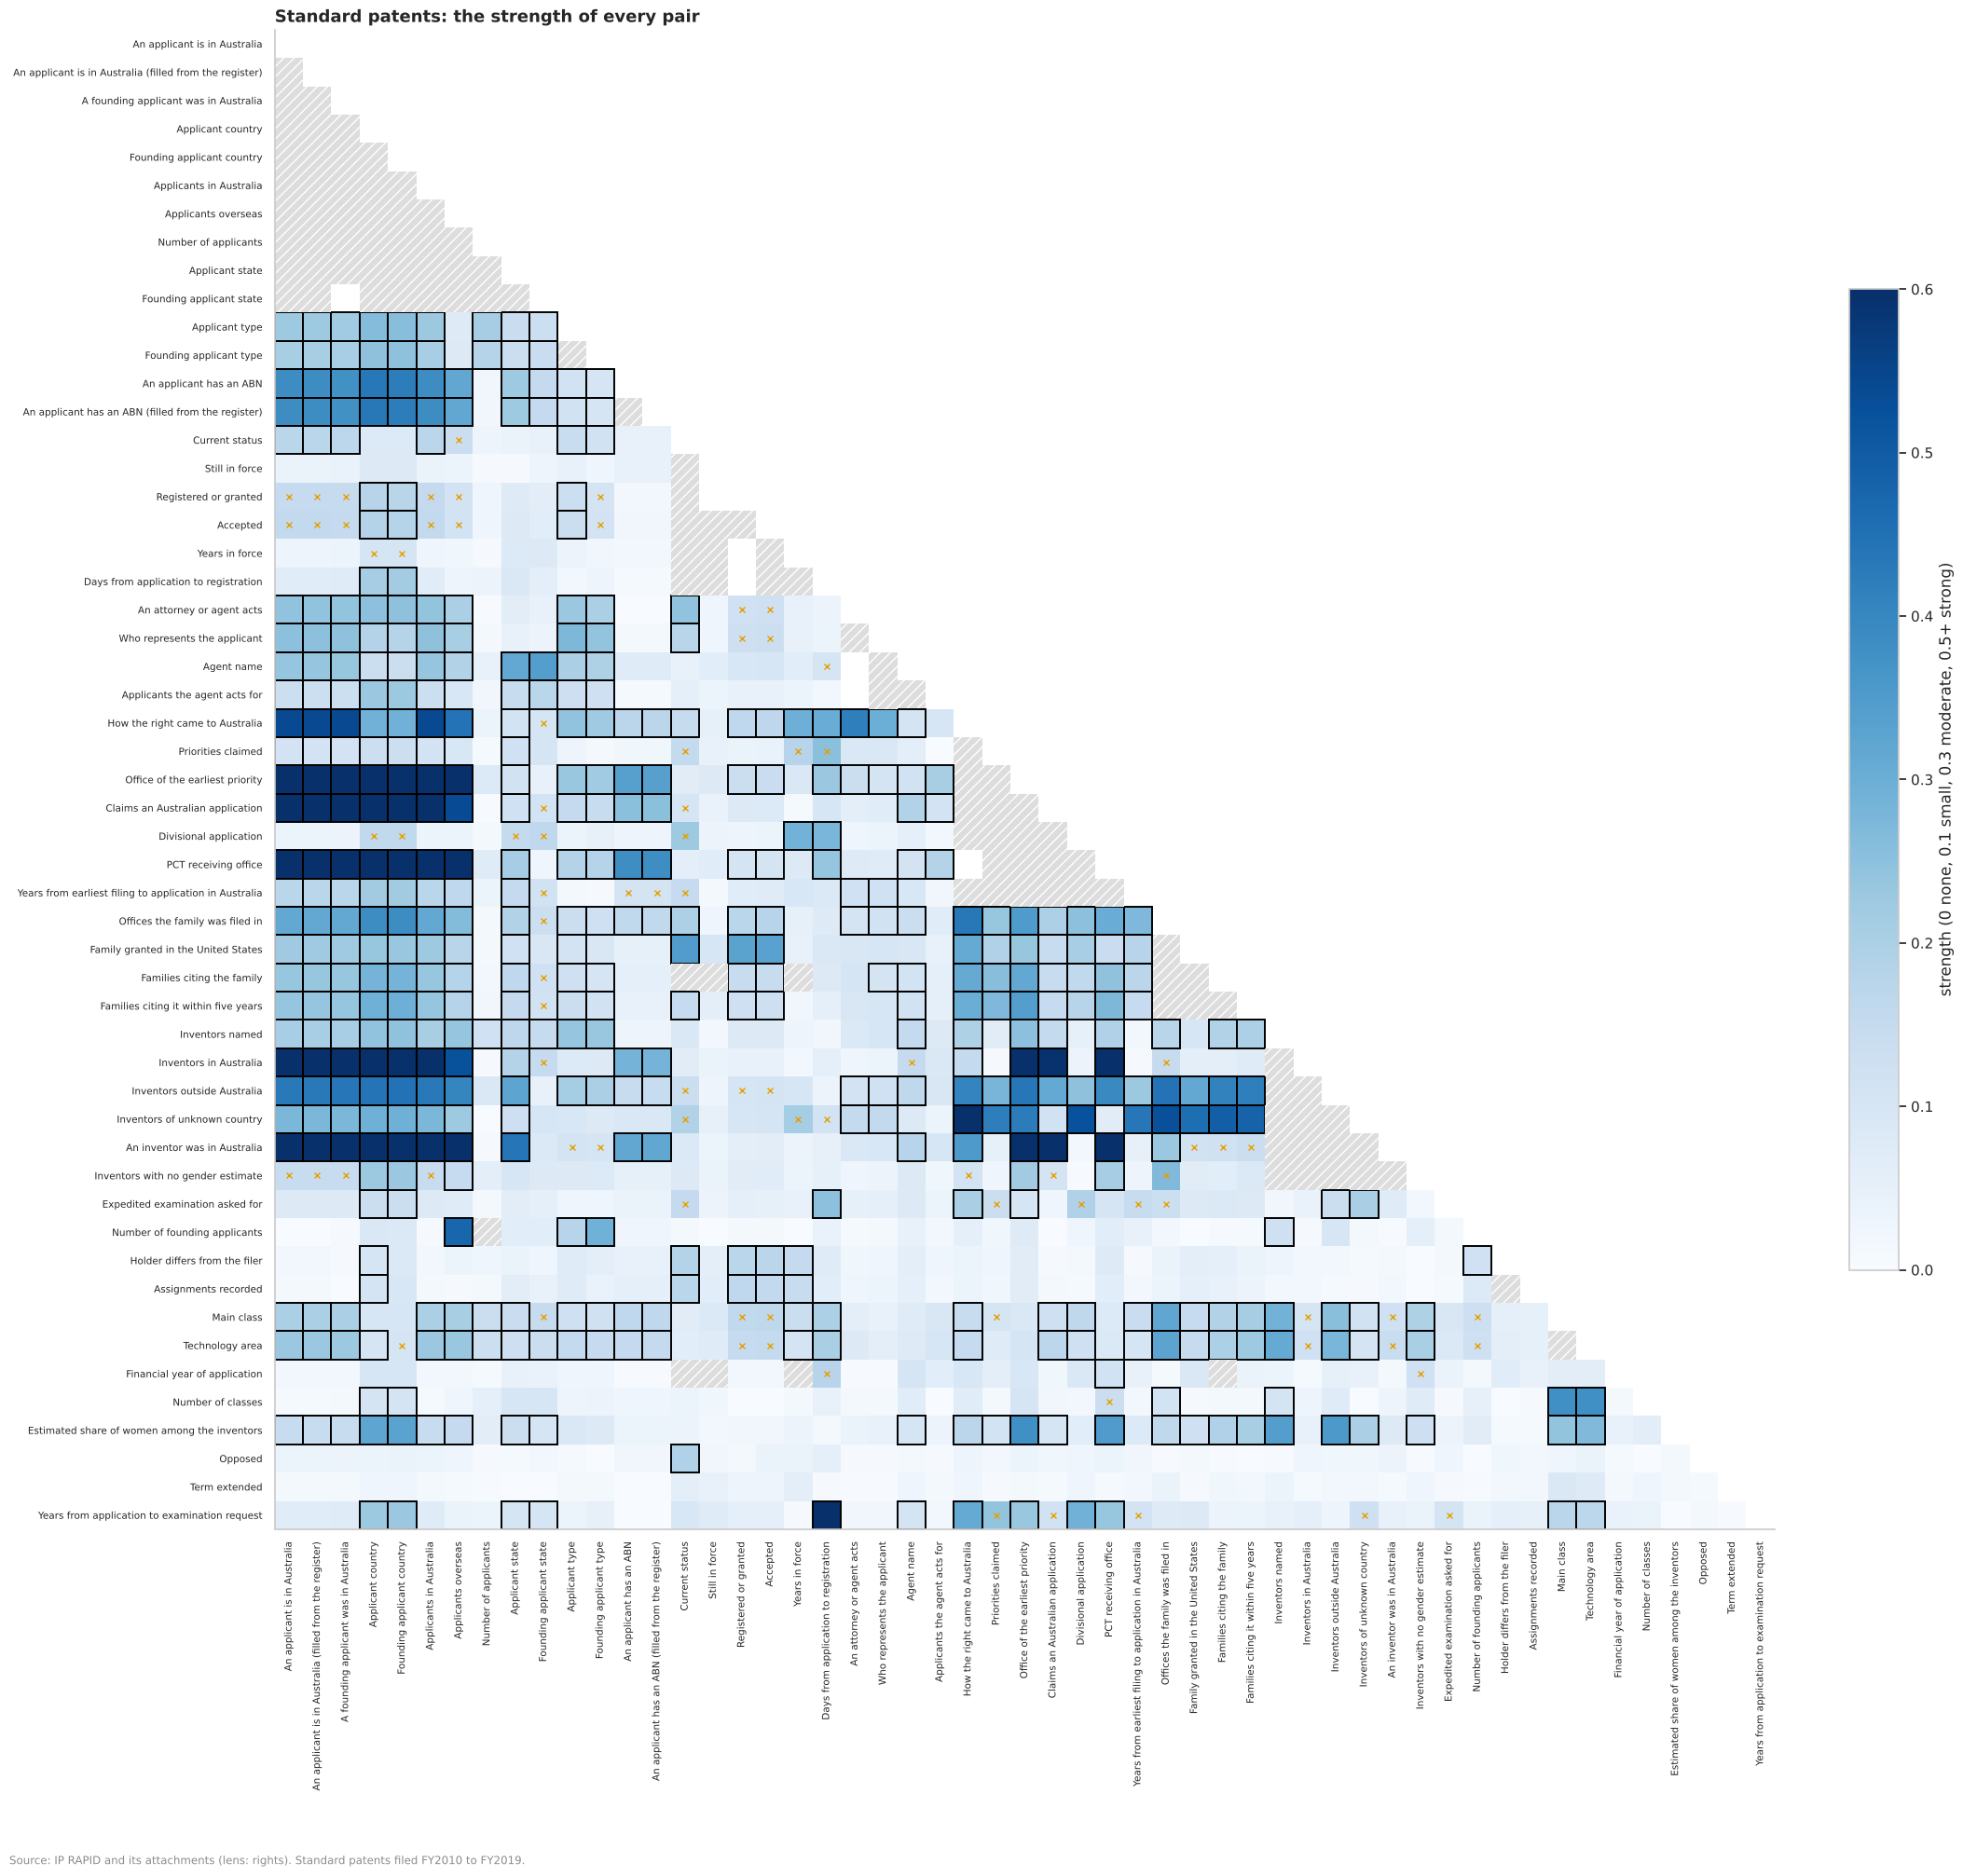

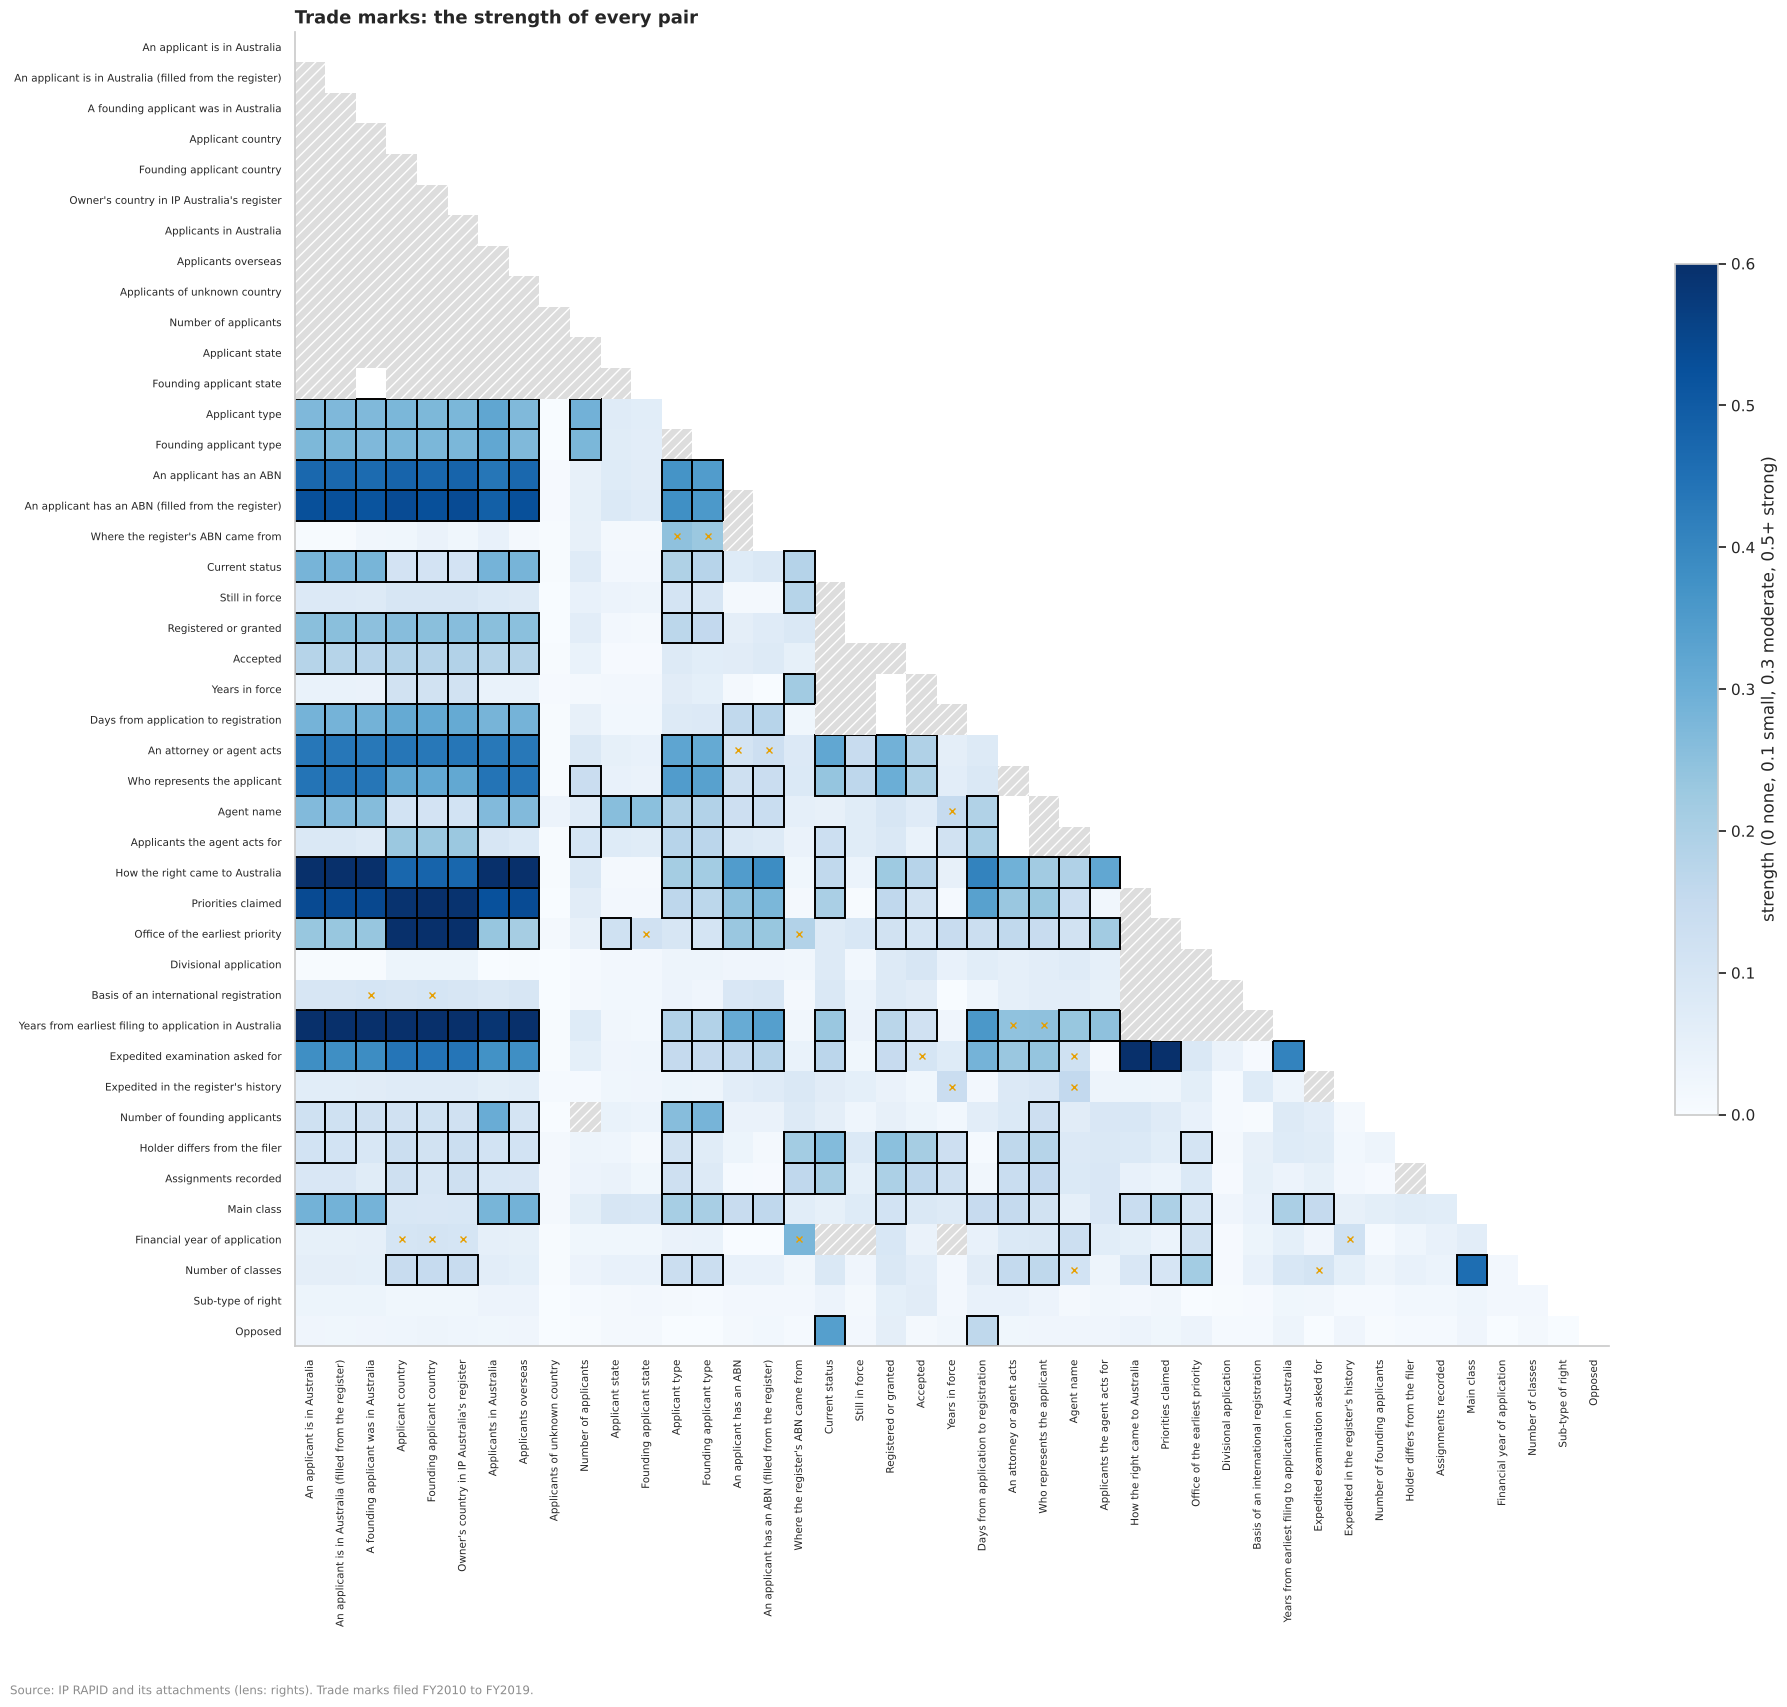

In [3]:
def screened_order(m):
    # the columns with at least one measured pair, in the order of their groups (so related measures sit together)
    measured = m.dropna(subset=["strength"])
    cols = set(measured["variable 1"]) | set(measured["variable 2"])
    grouped = [c for g in GROUPS.values() for c in g]
    return list(dict.fromkeys([c for c in grouped if c in cols] + sorted(cols)))


for t in ("standard", "trade_mark"):
    m = rights_screen[t]["verdicts"]
    fig = bi.strength_map(m, screened_order(m), label=lab, title=f"{RIGHT_TYPES[t]}: the strength of every pair")
    style.source(fig, f"IP RAPID and its attachments (lens: rights). {RIGHT_TYPES[t]} filed FY2010 to FY2019.")

Pairs measured in both samples: 5207
Agreement between the two samples' strengths (Spearman): 0.859
Leads whose strength differs between samples by more than 0.1: 264 of 1649


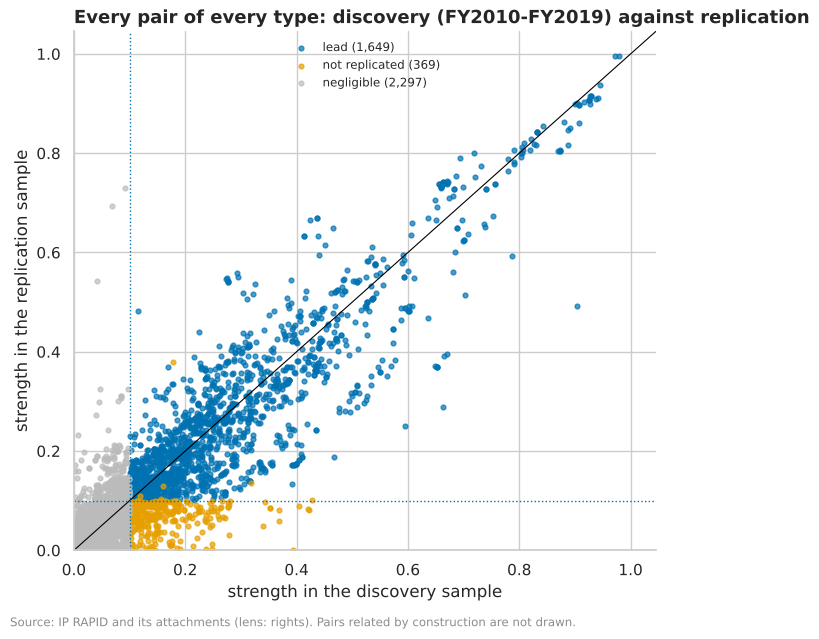

In [4]:
allv = pd.concat([s["verdicts"].assign(type=t) for t, s in rights_screen.items()])
fig = bi.replication_chart(allv, title="Every pair of every type: discovery (FY2010-FY2019) against replication")
style.source(fig, "IP RAPID and its attachments (lens: rights). Pairs related by construction are not drawn.")
print("Pairs measured in both samples:", allv["strength (replication)"].notna().sum())
ok = allv.dropna(subset=["strength", "strength (replication)"])
ok = ok[~ok["by construction"]]
print(
    "Agreement between the two samples' strengths (Spearman):",
    round(ok.strength.corr(ok["strength (replication)"], method="spearman"), 3),
)
print(
    "Leads whose strength differs between samples by more than 0.1:",
    int(((allv.verdict == "lead") & ((allv.strength - allv["strength (replication)"]).abs() > 0.1)).sum()),
    "of",
    int((allv.verdict == "lead").sum()),
)

The distinct leads, type by type (strength in discovery, its 95% interval, and in replication):

In [5]:
lead_tables = {}
for t in RIGHT_TYPES:
    s = rights_screen[t]
    lead_tables[t] = bi.leads_table(rights_leads[t], s["prepared"], s["discovery"], label=lab)
    print(f"\n{RIGHT_TYPES[t]}: {len(lead_tables[t])} distinct leads")
    with pd.option_context("display.max_rows", 100, "display.width", 250):
        display(lead_tables[t].round(3))


Standard patents: 59 distinct leads


,pair,measure,strength,95% interval,replication,size,versions,direction,candidate third factors
0,A founding applicant was in Australia × PCT receiving office,cramer_v,0.945,0.942 to 0.949,0.938,strong,47,True with au (17.9× chance),"Applicants in Australia, An applicant is in Australia, An applicant is in Australia (f..."
1,PCT receiving office × An inventor was in Australia,cramer_v,0.907,0.902 to 0.911,0.86,strong,27,au with True (16.5× chance),"Inventors in Australia, A founding applicant was in Australia, Applicants in Australia"
2,A founding applicant was in Australia × An inventor was in Australia,cramer_v,0.892,0.888 to 0.895,0.851,strong,45,True with True (14.1× chance),"PCT receiving office, Founding applicant country, Applicants in Australia"
3,Days from application to registration × Years from application to examination request,spearman,0.83,0.829 to 0.832,0.817,strong,1,rises with,"How the right came to Australia, Divisional application, Priorities claimed"
4,Offices the family was filed in × Inventors of unknown country,spearman,0.526,0.522 to 0.529,0.582,strong,12,falls with,"Inventors outside Australia, How the right came to Australia, Families citing the family"
5,Applicants overseas × Number of founding applicants,spearman,0.475,0.468 to 0.482,0.401,moderate,1,rises with,"Number of applicants, Main class, Technology area"
6,Applicant country × An applicant has an ABN (filled from the register),cramer_v,0.432,0.428 to 0.437,0.389,moderate,18,au with True (3.5× chance),"An applicant has an ABN, Founding applicant country, An applicant is in Australia"
7,How the right came to Australia × Offices the family was filed in,rank_eta,0.431,0.427 to 0.434,0.481,moderate,28,"Offices the family was filed in: highest median for pct (7), lowest for australian_pri...","Inventors of unknown country, Inventors outside Australia, Office of the earliest prio..."
8,An attorney or agent acts × How the right came to Australia,cramer_v,0.415,0.402 to 0.429,0.317,moderate,13,False with direct (27.2× chance),"Who represents the applicant, Applicant country, Founding applicant country"
9,Applicant country × Offices the family was filed in,rank_eta,0.386,0.383 to 0.390,0.489,moderate,32,"Offices the family was filed in: highest median for it (9), lowest for au (2)","Inventors outside Australia, Founding applicant country, Office of the earliest priority"



Trade marks: 45 distinct leads


,pair,measure,strength,95% interval,replication,size,versions,direction,candidate third factors
0,Expedited examination asked for × Priorities claimed,rank_eta,0.78,0.777 to 0.784,0.763,strong,3,"Priorities claimed: highest median for True (1), lowest for False (0)","How the right came to Australia, Founding applicant country, Owner's country in IP Aus..."
1,Founding applicant country × Office of the earliest priority,cramer_v,0.731,0.727 to 0.735,0.774,strong,33,at with at (91.8× chance),"Applicant country, Owner's country in IP Australia's register, Years from earliest fil..."
2,Applicant country × An applicant has an ABN (filled from the register),cramer_v,0.535,0.532 to 0.539,0.507,strong,16,se with False (1.8× chance),"Owner's country in IP Australia's register, An applicant is in Australia, An applicant..."
3,Main class × Number of classes,rank_eta,0.457,0.453 to 0.460,0.453,moderate,1,"Number of classes: highest median for 16 (3), lowest for 10 (1)","An attorney or agent acts, Applicant type, Founding applicant type"
4,Founding applicant country × Expedited examination asked for,cramer_v,0.444,0.438 to 0.448,0.385,moderate,8,at with True (3.3× chance),"Priorities claimed, How the right came to Australia, Owner's country in IP Australia's..."
5,Applicants in Australia × Who represents the applicant,rank_eta,0.442,0.439 to 0.445,0.427,moderate,31,"Applicants in Australia: highest median for self (1), lowest for attorney (0)","An applicant is in Australia (filled from the register), An applicant is in Australia,..."
6,Days from application to registration × How the right came to Australia,rank_eta,0.406,0.402 to 0.411,0.471,moderate,16,"Days from application to registration: highest median for divisional (620), lowest for...","Years from earliest filing to application in Australia, Priorities claimed, Founding a..."
7,An applicant has an ABN (filled from the register) × How the right came to Australia,cramer_v,0.385,0.382 to 0.388,0.337,moderate,8,False with madrid (1.7× chance),"An applicant is in Australia, An applicant is in Australia (filled from the register),..."
8,Applicant type × An applicant has an ABN (filled from the register),cramer_v,0.379,0.376 to 0.383,0.431,moderate,4,individual with False (1.8× chance),"An applicant has an ABN, Founding applicant type, Applicants in Australia"
9,Applicant type × Who represents the applicant,cramer_v,0.347,0.342 to 0.350,0.384,moderate,8,individual with self (2.0× chance),"Founding applicant type, An attorney or agent acts, Applicants in Australia"



Designs: 33 distinct leads


...

,pair,measure,strength,95% interval,replication,size,versions,direction,candidate third factors
0,Applicant type × An applicant has an ABN,cramer_v,0.757,0.751 to 0.763,0.738,strong,4,individual with False (1.8× chance),"An applicant has an ABN (filled from the register), Founding applicant type, Estimated..."
1,Applicants in Australia × Number of founding applicants,spearman,0.693,0.680 to 0.704,0.79,strong,1,rises with,"Number of applicants, Applicant type, Founding applicant type"
2,Number of founding applicants × Founding applicant type,rank_eta,0.23,0.224 to 0.237,0.22,small,2,"Number of founding applicants: highest mean for individual (1.187), lowest for organis...","Applicant type, Number of applicants, Applicants in Australia"
3,Applicant type × Applicants in Australia,rank_eta,0.221,0.214 to 0.227,0.254,small,11,"Applicants in Australia: highest mean for individual (1.144), lowest for organisation ...","Number of applicants, Number of founding applicants, Founding applicant type"
4,Applicant country × Estimated share of women among the register's inventors,rank_eta,0.207,0.202 to 0.214,0.196,small,7,Estimated share of women among the register's inventors: highest median for us (0.0028...,"Founding applicant country, An applicant is in Australia, An applicant is in Australia..."
5,Founding applicant type × Estimated share of women among the register's inventors,rank_eta,0.157,0.148 to 0.166,0.206,small,2,Estimated share of women among the register's inventors: highest median for organisati...,"Applicant type, An applicant has an ABN, An applicant has an ABN (filled from the regi..."
6,An applicant has an ABN (filled from the register) × Estimated share of women among th...,rank_eta,0.152,0.143 to 0.161,0.198,small,2,Estimated share of women among the register's inventors: highest median for True (0.07...,"Founding applicant type, Applicant type, An applicant has an ABN"
7,Applicant country × An applicant has an ABN,cramer_v,0.127,0.122 to 0.134,0.112,small,10,gi with True (2.1× chance),"Estimated share of women among the register's inventors, An applicant has an ABN (fill..."
8,An applicant has an ABN × Number of founding applicants,rank_eta,0.103,0.094 to 0.110,0.118,small,2,"Number of founding applicants: highest mean for False (1.127), lowest for True (1.057)","Founding applicant type, Applicant type, Inventors named in IP Australia's register (p..."



Second-tier patents: 63 distinct leads


,pair,measure,strength,95% interval,replication,size,versions,direction,candidate third factors
0,A founding applicant was in Australia × An inventor was in Australia,cramer_v,0.941,0.927 to 0.954,0.911,strong,32,True with True (3.0× chance),"Founding applicant country, An applicant is in Australia, An applicant is in Australia..."
1,A founding applicant was in Australia × Office of the earliest priority,cramer_v,0.916,0.905 to 0.926,0.903,strong,30,False with in (2.0× chance),"An applicant is in Australia, An applicant is in Australia (filled from the register),..."
2,Office of the earliest priority × An inventor was in Australia,cramer_v,0.88,0.849 to 0.901,0.863,strong,16,au with True (4.1× chance),"A founding applicant was in Australia, An applicant is in Australia, An applicant is i..."
3,Offices the family was filed in × Inventors outside Australia,spearman,0.72,0.707 to 0.730,0.751,strong,19,rises with,"Office of the earliest priority, How the right came to Australia, Inventors of unknown..."
4,Office of the earliest priority × Offices the family was filed in,rank_eta,0.686,0.666 to 0.705,0.755,strong,13,"Offices the family was filed in: highest median for tw (4), lowest for au (1)","Inventors outside Australia, How the right came to Australia, Families citing the family"
5,An applicant has an ABN × An inventor was in Australia,cramer_v,0.551,0.518 to 0.575,0.36,strong,4,True with True (2.3× chance),"An applicant has an ABN (filled from the register), Office of the earliest priority, A..."
6,Current status × An attorney or agent acts,cramer_v,0.491,0.482 to 0.500,0.474,moderate,12,lapsed with False (3.3× chance),"Registered or granted, Who represents the applicant, Years in force"
7,Applicant type × Who represents the applicant,cramer_v,0.458,0.444 to 0.467,0.382,moderate,8,individual with self (1.8× chance),"Founding applicant type, An attorney or agent acts, Applicants in Australia"
8,A founding applicant was in Australia × Agent name,cramer_v,0.454,0.444 to 0.471,0.355,moderate,23,False with leoniepat (2.1× chance),"An applicant is in Australia, An applicant is in Australia (filled from the register),..."
9,Founding applicant country × Offices the family was filed in,rank_eta,0.445,0.436 to 0.460,0.424,moderate,28,"Offices the family was filed in: highest median for vg (4), lowest for au (1)","Office of the earliest priority, Inventors outside Australia, Applicant country"



Plant breeder's rights: 14 distinct leads


,pair,measure,strength,95% interval,replication,size,versions,direction,candidate third factors
0,Applicant country × An attorney or agent acts,cramer_v,0.67,0.648 to 0.687,0.74,strong,26,au with False (2.1× chance),"Founding applicant country, An applicant is in Australia, An applicant is in Australia..."
1,Founding applicant type × Agent name,cramer_v,0.573,0.539 to 0.611,0.446,strong,2,individual with 2021c22c-85e8-42f5-8ea7-6662f6a0fb0f (3.7× chance),"Applicant type, Main class, Founding applicant country"
2,Number of applicants × Holder differs from the filer,rank_eta,0.531,0.478 to 0.593,0.482,strong,4,"Number of applicants: highest mean for True (1.392), lowest for False (1)","Main class, Applicants in Australia, Founding applicant state"
3,Applicants overseas × Main class,rank_eta,0.513,0.487 to 0.534,0.544,strong,9,"Applicants overseas: highest median for vitis (1), lowest for brassica (0)","An applicant is in Australia, An applicant is in Australia (filled from the register),..."
4,Main class × Agent name,cramer_v,0.489,0.470 to 0.510,0.414,moderate,4,rosa with 1bb69e3e-2d07-4cec-a900-d5b8b0a340ce (26.1× chance),"Applicants overseas, An applicant is in Australia, An applicant is in Australia (fille..."
5,Agent name × Still in force,cramer_v,0.45,0.417 to 0.492,0.488,moderate,11,3362bc56-4677-460b-9bea-0556c88221d2 with False (2.5× chance),"Years in force, Main class, Current status"
6,Days from application to registration × Main class,rank_eta,0.336,0.314 to 0.377,0.357,moderate,5,"Days from application to registration: highest median for citrus (2,692), lowest for s...","Agent name, Applicant state, Years in force"
7,Applicant type × Main class,cramer_v,0.296,0.283 to 0.324,0.276,small,2,individual with rosa (2.1× chance),"Agent name, Founding applicant type, Founding applicant country"
8,Financial year of application × Agent name,rank_eta,0.276,0.257 to 0.334,0.224,small,1,Financial year of application: highest median for 53bf33ed-b1db-4330-a97f-be61722e90ac...,"Years in force, Current status, Still in force"
9,Days from application to registration × Applicant state,rank_eta,0.27,0.212 to 0.340,0.319,small,30,"Days from application to registration: highest median for other (1,329), lowest for sa...","Main class, Founding applicant state, Applicant country"


In [6]:
# A record quirk the screen points to (designs: status against applicants of unknown country): IP RAPID's origin of
# designs by status, and after the register's fill (ADR 0029)
sql("""
    SELECT CASE WHEN filing_fy >= 2010 THEN 'FY2010-FY2019' ELSE 'FY2000-FY2009' END AS period, status,
           count(*) AS designs,
           100 * avg((applicants_country_unknown > 0)::int) AS "an applicant of unknown country (%)",
           100 * avg((australian_applicant IS NULL)::int) AS "origin unknown (%)",
           100 * avg((australian_applicant_filled IS NULL)::int) AS "origin unknown, filled (%)"
    FROM {lens/rights} WHERE ip_right_type = 'design' AND filing_fy BETWEEN 2000 AND 2019
    GROUP BY ALL HAVING count(*) >= 100 ORDER BY 1, 3 DESC
""").set_index(["period", "status"]).round(2)

designs  an applicant of unknown country (%)  origin unknown (%)  origin unknown, filled (%)
period        status                                                                                                  
FY2000-FY2009 ceased        45348                                 0.08                0.07                        0.07
              lapsed         5035                                  100                 100                        0.73
              withdrawn       560                                  100                 100                        0.89
FY2010-FY2019 ceased        53008                                 0.22                0.22                        0.22
              registered     9880                                 0.01                0.01                        0.01
              lapsed         2680                                  100                 100                        1.12
              certified      2204                                    0                   0                           0
              withdrawn       446                                99.78                 100                        3.81

#### Observations
**B1 (descriptive). The screen of the rights lens: 223 distinct leads, all of them past the correction for the
number of pairs, most of them holding in a second decade.**
- Six types of right were screened, each on up to 200,000 rights filed FY2010 to FY2019 and again on those filed
  FY2000 to FY2009; 23 (provisionals) to 53 (standard patents) variables had at least one measured pair.
- **Leads:** 490 pairs for standard patents, 304 for trade marks, 271 for designs, 41 for provisionals, 436 for
  second-tier patents and 107 for plant breeder's rights; as distinct pairs of measures, 59, 45, 33, 9, 63 and 14
  (223 in all, as printed). 85, 22, 68, 7, 158 and 29 pairs passed in the first decade but did not hold in the second.
- **No pair failed on the correction alone** ("not significant": 0 for every type): with samples this large the
  conventional threshold of 0.1 and the second decade did all the sorting, as expected.
- **The two decades agree closely:** across the 5,207 pairs measured in both, the strengths' order agrees with a
  Spearman rho of 0.859. Of 1,649 leads, 264 differ between the decades by more than 0.1, so a lead's size is often
  period-specific even when its existence is not.

**B2 (descriptive). The strongest leads are mechanics of the IP system, recorded and not carried forward.** Each is
expected from how rights are filed and recorded:
- Australian filers file their PCT applications at IP Australia (filer origin × PCT receiving office 0.945, interval
  0.942 to 0.949; 0.938 in FY2000 to FY2009; the filer in Australia with `au` 17.9 times chance), and the inventions
  they file are made here (filer origin × an inventor in Australia 0.892, interval 0.888 to 0.895; 0.851).
- A standard patent's time to grant rises with the time its owner waits before asking for examination (rho 0.83,
  interval 0.829 to 0.832; 0.817): the applicant, not only the office, sets the pace.
- Wider families have fewer inventors of unknown country (rho 0.526; 0.582): Google Patents takes inventors' countries
  from foreign publications, which narrow families lack (U95).
- Trade marks: expedited examination goes with a priority claim (0.78; 0.763), the recording U103 explained, and a
  founding applicant's country with its priority office (0.731; 0.774).
- Provisionals: individuals have no ABN (0.757; 0.738).

**B3 (descriptive). A record quirk: IP RAPID gives no applicant country for designs that were never registered.** The
screen's strongest design pair is status against applicants of unknown country (0.98, interval 0.976 to 0.982; 0.996
in FY2000 to FY2009). In the table above, every lapsed and every withdrawn design in both decades is of unknown
origin in IP RAPID (100%), against 0.22% of ceased and 0.01% of registered ones filed FY2010 to FY2019. The register's
countries fill nearly all of them (after the fill, 1.12% of lapsed and 3.81% of withdrawn designs filed FY2010 to
FY2019 remain unknown). So IP RAPID's "origin unknown" designs (U7, U13) are, in recent decades, the applications that
never reached registration: an origin comparison on IP RAPID alone drops failed applications, and must use the
filled origin (ADR 0029).

**B4 (observational). The substantive leads, and where each is followed up.** Read with their candidate third
factors (above); all hold in both decades:
- **Representation and outcome** (section 1.1): a standard patent with no attorney or agent is more often withdrawn
  (status × an agent acts 0.243; 0.217; withdrawn with no agent 28.0 times chance), as are trade marks (0.317;
  0.274), second-tier patents (0.491; 0.474) and designs filed through an agent who is not an attorney (representation
  × registered 0.323; 0.281).
- **Origin and reach** (1.3): the offices a standard patent's family is filed in vary with its route (0.431; 0.481),
  the applicant's country (0.386; 0.489: a median of 2 for Australian applicants, 9 for Italian) and the technology
  (0.328; 0.31: organic fine chemistry a median of 11).
- **Technology and inventors' gender** (1.6): the estimated share of women among a standard patent's inventors
  varies with the technology area (0.268; 0.297; biotechnology highest). Its strongest leads, with the priority
  office (0.378) and the applicant's country (0.329), are led by China, whose estimates U97 found unreliable: a
  quirk of the name dictionary, not a finding. Provisionals' inventors: organisations' have more women than
  individuals' (0.157; 0.206).
- **Place and representation:** the founding applicant's state goes with the attorney firm (0.342; 0.389; South
  Australia with Collison & Co 14.9 times chance): attorney markets are local.
- **Trade marks:** individuals go with clothing (class 25, 2.1 times chance; applicant type × class 0.207; 0.205);
  overseas applicants with medical apparatus (class 10, 1.9 times; 0.287; 0.294); attorneys file more classes per
  mark (a mean 1.958 against 1.466 for applicants filing alone; 0.163; 0.154).
- **Lifetimes:** designs' years in force vary with the Locarno class (0.288; 0.221: a median 9.41 years for class 04,
  5 for class 02, clothing); second-tier patents' with the applicant's country (0.379; 0.217: China lowest, a median
  2.54 years) and with having an ABN (0.201; 0.198: a median 6.54 years against 3.54).
- **Plant breeder's rights:** the genus goes with overseas applicants (0.513; 0.544; grapes, `vitis`, highest) and with
  the time to grant (0.336; 0.357; citrus a median 2,692 days).

### 1.1 Filing alone, and what comes of it, by origin, applicant type and representation

**From:** U11, U20, U33. **Informs:** Q2, Q4. Who files without an attorney, and whether those applications are
granted or registered as often, and as fast. Decided years only (filed FY2000 to FY2019); both periods shown.

share                           n              
period                              FY2000-FY2009 FY2010-FY2019 FY2000-FY2009 FY2010-FY2019
t          filer                                                                           
design     Australian individuals          0.0215        0.2279          8144          5898
           Australian organisations        0.2119        0.2044         14555         19634
           overseas individuals            0.0102        0.0689          1568          2235
           overseas organisations          0.0079        0.0112         21117         37289
standard   Australian individuals          0.1977        0.2606          8047          6320
           Australian organisations        0.0697        0.0352         16471         19330
           overseas individuals            0.0135        0.0114         15877         14483
           overseas organisations          0.0014        0.0028        196232        235507
trade_mark Australian individuals          0.5882        0.6829         90482        112275
           Australian organisations        0.4267        0.4023        245437        318331
           overseas individuals            0.2233        0.1074          8495         10722
           overseas organisations          0.1047        0.0537        156638        235831

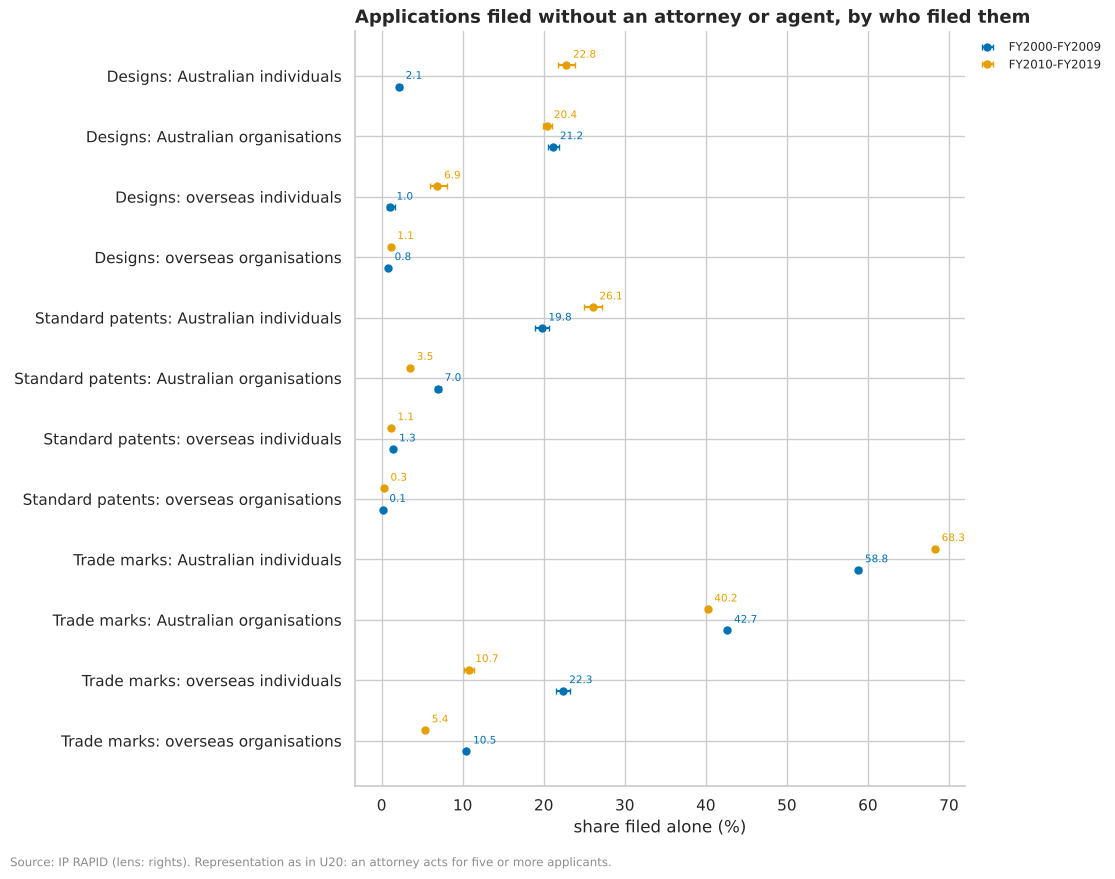

In [7]:
FILER = "CASE WHEN founding_australian THEN 'Australian ' ELSE 'overseas ' END || founder_type || 's'"
PERIOD = (
    "CASE WHEN filing_fy BETWEEN 2010 AND 2019 THEN 'FY2010-FY2019'"
    " WHEN filing_fy BETWEEN 2000 AND 2009 THEN 'FY2000-FY2009' END"
)
SHORT = {"standard": "Standard patents", "trade_mark": "Trade marks", "design": "Designs"}


def rsql(q, **kw):
    # sql() with the shorthands @FILER (who filed: origin and type) and @PERIOD (the two decades)
    return sql(q.replace("@FILER", FILER).replace("@PERIOD", PERIOD), **kw)


rep = rsql("""
    SELECT coalesce(patent_type, ip_right_type) AS t, @PERIOD AS period, @FILER AS filer, representation,
           count(*) AS n, count(*) FILTER (registered_date IS NOT NULL) AS registered,
           count(*) FILTER (exam_requested_date IS NOT NULL) AS exam_requested
    FROM {lens/rights}
    WHERE filing_fy BETWEEN 2000 AND 2019
      AND coalesce(patent_type, ip_right_type) IN ('standard', 'trade_mark', 'design')
      AND founding_australian IS NOT NULL AND founder_type IS NOT NULL AND representation IS NOT NULL
    GROUP BY ALL
""")
alone = (
    rep.assign(alone=rep.n.where(rep.representation == "self", 0))
    .groupby(["t", "filer", "period"])[["alone", "n"]]
    .sum()
)
alone["share"] = alone.alone / alone.n
alone["low"], alone["high"] = bi.wilson(alone.alone, alone.n)
plot = alone.reset_index()
plot.index = plot.t.map(SHORT) + ": " + plot.filer
fig = bi.dot_chart(
    plot,
    value="share",
    low="low",
    high="high",
    hue="period",
    title="Applications filed without an attorney or agent, by who filed them",
    xlabel="share filed alone",
)
style.source(fig, "IP RAPID (lens: rights). Representation as in U20: an attorney acts for five or more applicants.")
alone.unstack("period")[["share", "n"]].round(4)

In [8]:
# Among Australian filers: how often an application is granted or registered, by representation, and the gap between
# an attorney and filing alone (percentage points, with Newcombe's 95% interval)
au = (
    rep[rep.filer.str.startswith("Australian")]
    .groupby(["t", "filer", "period", "representation"])[["registered", "exam_requested", "n"]]
    .sum()
)
au["granted (%)"] = 100 * au.registered / au.n
lo, hi = bi.wilson(au.registered, au.n)
au["low"], au["high"] = 100 * lo, 100 * hi
display(au[["n", "granted (%)", "low", "high"]].round(1).unstack("period"))
gaps = []
for (t, filer, period), d in au.groupby(level=[0, 1, 2]):
    d = d.droplevel([0, 1, 2])
    if {"attorney", "self"} <= set(d.index):
        a, s = d.loc["attorney"], d.loc["self"]
        diff, dl, dh = bi.rate_difference(a.registered, a.n, s.registered, s.n)
        row = {
            "type": SHORT[t],
            "filer": filer,
            "period": period,
            "attorney - alone (points)": 100 * diff,
            "low": 100 * dl,
            "high": 100 * dh,
        }
        if t == "standard":
            # the same gap among applications whose examination was requested (a standard patent is granted only
            # after examination)
            diff, dl, dh = bi.rate_difference(a.registered, a.exam_requested, s.registered, s.exam_requested)
            row |= {
                "among examined (points)": 100 * diff,
                "low (examined)": 100 * dl,
                "high (examined)": 100 * dh,
                "examination requested: attorney (%)": 100 * a.exam_requested / a.n,
                "examination requested: alone (%)": 100 * s.exam_requested / s.n,
            }
        gaps.append(row)
pd.DataFrame(gaps).set_index(["type", "filer", "period"]).round(1)

n                 granted (%)                         low                        high  \
period                                             FY2000-FY2009 FY2010-FY2019 FY2000-FY2009 FY2010-FY2019 FY2000-FY2009 FY2010-FY2019 FY2000-FY2009   
t          filer                    representation                                                                                                     
design     Australian individuals   attorney                2470          2527           100           100          99.8          99.8           100   
                                    other_agent             5499          2027           100           100          99.9          99.8           100   
                                    self                     175          1344           100          99.9          97.9          99.5           100   
           Australian organisations attorney               10230         14910           100          99.9           100          99.9           100   
                                    other_agent             1241           711           100          99.4          99.7          98.6           100   
                                    self                    3084          4013           100          99.9          99.9          99.7           100   
standard   Australian individuals   attorney                5447          4425          45.2          40.8          43.9          39.3          46.5   
                                    other_agent             1009           248          27.7          22.6            25          17.8          30.5   
                                    self                    1591          1647           8.3           4.9             7           3.9           9.8   
           Australian organisations attorney               15104         18579            56          49.7          55.2            49          56.8   
                                    other_agent              219            71          47.9          16.9          41.4           9.9          54.5   
                                    self                    1148           680          62.1           9.7          59.3           7.7          64.9   
trade_mark Australian individuals   attorney               13908         24417          71.6          73.9          70.9          73.3          72.4   
                                    other_agent            23355         11191          49.9          62.9          49.2            62          50.5   
                                    self                   53219         76667          48.5          49.6            48          49.3          48.9   
           Australian organisations attorney              120718        169463          75.2          77.8          74.9          77.6          75.4   
                                    other_agent            19994         20801          58.7          62.5            58          61.9          59.3   
                                    self                  104725        128067          53.9          54.2          53.6          53.9          54.2   

                                                                  
period                                             FY2010-FY2019  
t          filer                    representation                
design     Australian individuals   attorney                 100  
                                    other_agent              100  
                                    self                     100  
           Australian organisations attorney                99.9  
                                    other_agent             99.8  
                                    self                     100  
standard   Australian individuals   attorney                42.2  
                                    other_agent             28.2  
                                    self                       6  
           Australian organisations attorney                50.4  

attorney - alone (points)  low  high  among examined (points)  low (examined)  high (examined)  \
type             filer                    period                                                                                                          
Designs          Australian individuals   FY2000-FY2009                          0 -0.2   2.1                      NaN             NaN              NaN   
                                          FY2010-FY2019                        0.1 -0.1   0.5                      NaN             NaN              NaN   
                 Australian organisations FY2000-FY2009                          0   -0   0.1                      NaN             NaN              NaN   
                                          FY2010-FY2019                          0 -0.1   0.2                      NaN             NaN              NaN   
Standard patents Australian individuals   FY2000-FY2009                       36.9 34.9  38.7                     33.8            29.5             37.7   
                                          FY2010-FY2019                       35.9 34.1  37.6                     34.5            30.1             38.4   
                 Australian organisations FY2000-FY2009                       -6.1 -8.9  -3.1                    -17.7           -20.2              -15   
                                          FY2010-FY2019                         40 37.5  42.1                     25.3            18.6             31.4   
Trade marks      Australian individuals   FY2000-FY2009                       23.2 22.3    24                      NaN             NaN              NaN   
                                          FY2010-FY2019                       24.3 23.6  24.9                      NaN             NaN              NaN   
                 Australian organisations FY2000-FY2009                       21.3 20.9  21.6                      NaN             NaN              NaN   
                                          FY2010-FY2019                       23.6 23.3  23.9                      NaN             NaN              NaN   

                                                         examination requested: attorney (%)  examination requested: alone (%)  
type             filer                    period                                                                                
Designs          Australian individuals   FY2000-FY2009                                  NaN                               NaN  
                                          FY2010-FY2019                                  NaN                               NaN  
                 Australian organisations FY2000-FY2009                                  NaN                               NaN  
                                          FY2010-FY2019                                  NaN                               NaN  
Standard patents Australian individuals   FY2000-FY2009                                 75.9                              32.1  
                                          FY2010-FY2019                                 75.9                              25.3  
                 Australian organisations FY2000-FY2009                                 84.2                              73.7  
                                          FY2010-FY2019                                 86.2                                30  
Trade marks      Australian individuals   FY2000-FY2009                                  NaN                               NaN  
                                          FY2010-FY2019                                  NaN                               NaN  
                 Australian organisations FY2000-FY2009                                  NaN                               NaN  
                                          FY2010-FY2019                                  NaN                               NaN

In [9]:
# Time to grant for standard patents granted: from application, and from the examination request (the part the
# office controls more), by who filed them; medians with 95% bootstrap intervals for the differences
ttg = rsql(
    """
    SELECT @PERIOD AS period, @FILER AS filer, representation, days_to_registration / 365.25 AS years,
           date_diff('day', exam_requested_date, registered_date) / 365.25 AS years_after_request
    FROM {lens/rights}
    WHERE patent_type = 'standard' AND filing_fy BETWEEN 2000 AND 2019 AND registered_date IS NOT NULL
      AND days_to_registration >= 0 AND founding_australian IS NOT NULL AND founder_type IS NOT NULL
""",
    max_rows=None,
)
display(
    ttg.groupby(["filer", "period"])[["years", "years_after_request"]]
    .agg(["median", "size"])
    .round(2)
    .unstack("period")
)
rows = []
for period, d in ttg.groupby("period"):
    ref = d[d.filer == "overseas organisations"]
    for filer in ("Australian organisations", "Australian individuals"):
        g = d[d.filer == filer]
        for col in ("years", "years_after_request"):
            diff, lo, hi = bi.median_difference(g[col], ref[col])
            rb = bi.compare_groups(pd.Series(np.r_[g[col], ref[col]]), pd.Series([0] * len(g) + [1] * len(ref)))
            rows.append(
                {
                    "period": period,
                    "filer": filer,
                    "measure": col,
                    "median difference (years)": diff,
                    "low": lo,
                    "high": hi,
                    "rank-biserial": rb["rank-biserial"],
                }
            )
pd.DataFrame(rows).set_index(["measure", "filer", "period"]).sort_index().round(3)

years                                           years_after_request                                          
                                median                        size                            median                        size              
period                   FY2000-FY2009 FY2010-FY2019 FY2000-FY2009 FY2010-FY2019       FY2000-FY2009 FY2010-FY2019 FY2000-FY2009 FY2010-FY2019
filer                                                                                                                                         
Australian individuals             3.3          3.05          2873          1940                 1.8          1.72          2873          1940
Australian organisations           3.4          3.12          9281          9316                2.07          1.86          9281          9316
overseas individuals               3.3          2.86          8733          8065                2.12          1.71          8733          8065
overseas organisations            3.32          2.65        125437        161358                2.15          1.69        125437        161358

median difference (years)    low   high  rank-biserial
measure             filer                    period                                                               
years               Australian individuals   FY2000-FY2009                     -0.019 -0.126  0.085         -0.036
                                             FY2010-FY2019                        0.4  0.289  0.501           0.12
                    Australian organisations FY2000-FY2009                      0.077  0.044  0.126          0.016
                                             FY2010-FY2019                      0.476   0.43   0.52          0.179
years_after_request Australian individuals   FY2000-FY2009                     -0.342 -0.386 -0.304         -0.229
                                             FY2010-FY2019                      0.036 -0.003  0.082          0.005
                    Australian organisations FY2000-FY2009                     -0.079 -0.101 -0.057         -0.067
                                             FY2010-FY2019                       0.17  0.153  0.184          0.118

The rank-biserial correlation compares two groups by ranks: it is the chance that a patent from the first group takes
longer than one from overseas organisations, minus the reverse chance (from -1 to 1; 0 when neither tends to take
longer).

#### Observations
**B5 (observational). Australian individuals file alone far more than anyone else; organisations and overseas filers
almost never do, for patents.** Share filed with no attorney or agent, FY2010 to FY2019 (FY2000 to FY2009):
- **Standard patents:** Australian individuals 26.06% (19.77%), Australian organisations 3.52% (6.97%), overseas
  individuals 1.14% (1.35%), overseas organisations 0.28% (0.14%).
- **Trade marks:** Australian individuals 68.29% (58.82%), Australian organisations 40.23% (42.67%), overseas
  organisations 5.37% (10.47%).
- **Designs do not replicate:** Australian individuals filed 22.79% of their designs alone in FY2010 to FY2019 but
  2.15% in FY2000 to FY2009, when 5,499 of their 8,144 designs went through an agent who is not an attorney.
  How agents were recorded for designs seems to have changed between the decades; design representation is compared
  within one decade only.

**B6 (observational). Standard patents filed alone are rarely granted; the gap is about 36 points for Australian
individuals in both decades, and holds among applications that were examined.**
- **Australian individuals:** 4.9% of standard patents filed alone were granted (interval 3.9% to 6.0%) against 40.8%
  with an attorney (39.3% to 42.2%), FY2010 to FY2019: a gap of 35.9 points (34.1 to 37.6). FY2000 to FY2009: 8.3%
  against 45.2%, a gap of 36.9 points (34.9 to 38.7).
- **Among those whose examination was requested,** the gap stays: 34.5 points (30.1 to 38.4) and 33.8 (29.5 to 37.7).
  Filing alone also goes with not asking for examination: 25.3% of individuals' lone applications against 75.9% with
  an attorney (FY2010 to FY2019).
- **Australian organisations do not replicate:** a gap of 40.0 points (37.5 to 42.1) in FY2010 to FY2019, but -6.1
  (-8.9 to -3.1) in FY2000 to FY2009, when the 1,148 organisations filing alone were granted 62.1% of the time. The
  earlier decade's lone organisations look like firms with their own patent staff, which the later decade's do not.
- **Trade marks** replicate for both: with an attorney, Australian individuals' marks are registered 24.3 points more
  often (23.6 to 24.9; FY2000 to FY2009: 23.2, 22.3 to 24.0), organisations' 23.6 points (23.3 to 23.9; 21.3).
  **Designs** are registered without examination, so 99.4% to 100% are, whoever files.
- **Not a cause.** Representation counts an agent on the record at any time, so an application dropped early may
  never appoint one (the arrow can run backwards), and those who file alone differ in resources and experience.
  Candidate third factors: applicant type and origin (the screen's applicant type × representation, 0.272; 0.277),
  whether examination is requested, the route of filing. Q4 asks whether help to file would add value; this is the
  lead.

**B7 (observational). Australian organisations' standard patents took longer to grant than overseas organisations' in
FY2010 to FY2019, but not in FY2000 to FY2009: not a lead.** Granted standard patents, median years from application:
Australian organisations 3.12 against 2.65 for overseas organisations (a difference of 0.476 years, interval 0.43 to
0.52; rank-biserial 0.179), but 3.40 against 3.32 in FY2000 to FY2009 (0.077, 0.044 to 0.126; 0.016). From the
examination request the difference is 0.17 years (0.153 to 0.184) in the later decade and -0.079 (-0.101 to -0.057) in
the earlier. The route is the candidate third factor: a PCT application's clock starts at national phase entry,
about 30 months after its priority (U6), and overseas filers use the PCT most (section 1.5); the screen ties time to
grant to the route (0.304; 0.237: claiming an Australian application, a median 1,617 days).

### 1.2 Years in force, by origin, applicant type and technology

**From:** U36. **Informs:** Q1. How long owners keep a right is a sign of the value they expect from it (renewal fees
must be paid). Survival curves, with rights still in force kept as unfinished, for rights granted or registered.
Standard patents: filed FY2005 to FY2009 (discovery) against FY2000 to FY2004 (replication), so that both have reached
15 years. For patents filed before FY2003 the founding applicant may be a later holder (U35), a caution for the
replication period.

in force                         low                        high                     at risk              
period                         FY2000-FY2004 FY2005-FY2009 FY2000-FY2004 FY2005-FY2009 FY2000-FY2004 FY2005-FY2009 FY2000-FY2004 FY2005-FY2009
group                    years                                                                                                                
Australian individuals   5              99.8          99.1          99.4          98.4          99.9          99.5         1,530         1,330
                         10             55.3          66.4          52.8          63.8          57.7          68.8           848           896
                         15               27          35.6          24.8            33          29.2          38.1           414           499
Australian organisations 5               100          99.9          99.8          99.8           100           100         4,548         4,732
                         10             72.8          78.7          71.5          77.5          74.1          79.9         3,313         3,740
                         15             42.4          50.3          40.9          48.9          43.8          51.8         1,930         2,383
overseas individuals     5               100          99.9          99.8          99.7           100          99.9         4,679         4,054
                         10             55.4          68.6            54          67.1          56.9            70         2,595         2,800
                         15             28.9          38.7          27.6          37.2          30.2          40.2         1,352         1,570
overseas organisations   5               100           100           100          99.9           100           100     6.441e+04       6.1e+04
                         10             62.9          72.3          62.5          71.9          63.3          72.6     4.054e+04     4.411e+04
                         15             36.8          43.9          36.5          43.5          37.2          44.3     2.374e+04     2.679e+04

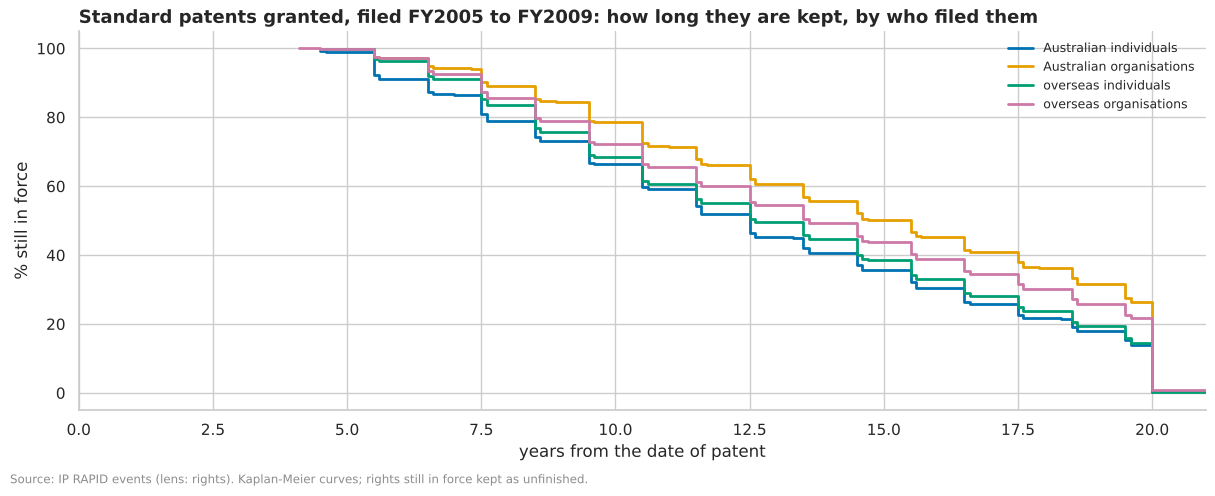

In [10]:
def lifetimes(where, group, periods):
    # Kaplan-Meier curves of years in force by group and period; returns the curves keyed 'group | period'
    case = "CASE " + " ".join(f"WHEN filing_fy BETWEEN {a} AND {b} THEN 'FY{a}-FY{b}'" for a, b in periods) + " END"
    c = rsql(f"""
        SELECT {group} AS grp, {case} AS period, round(years_in_force, 1) AS t,
               count(*) FILTER (NOT in_force) AS ended, count(*) FILTER (in_force) AS unfinished
        FROM {{lens/rights}}
        WHERE {where} AND years_in_force >= 0 AND in_force IS NOT NULL GROUP BY ALL
    """).dropna(subset=["grp", "period"])
    c["key"] = c.grp + " | " + c.period
    return uni.kaplan_meier(c, by="key")


def at_years(km, years):
    # the share in force at each of `years`, with its interval, as rows of group and period
    out = []
    for y in years:
        s = bi.survival_with_interval(km, y, by="key").reset_index()
        s[["group", "period"]] = s.key.str.split(" | ", regex=False, expand=True)
        out.append(s.assign(years=y))
    return pd.concat(out).set_index(["group", "years", "period"]).drop(columns="key").sort_index()


STD = "patent_type = 'standard' AND founding_australian IS NOT NULL AND founder_type IS NOT NULL"
km_std = lifetimes(STD, "@FILER", [(2005, 2009), (2000, 2004)])
std_life = at_years(km_std, [5, 10, 15])
fig, ax = plt.subplots(figsize=(12, 4.6))
for i, (key, d) in enumerate(km_std[km_std.key.str.endswith("FY2005-FY2009")].groupby("key")):
    ax.step(d.t, 100 * d.survival, where="post", lw=2, color=style.PALETTE[i], label=key.split(" | ")[0])
ax.set_xlabel("years from the date of patent")
ax.set_ylabel("% still in force")
ax.set_xlim(0, 21)
ax.legend(frameon=False, fontsize=9)
ax.set_title("Standard patents granted, filed FY2005 to FY2009: how long they are kept, by who filed them")
style.source(fig, "IP RAPID events (lens: rights). Kaplan-Meier curves; rights still in force kept as unfinished.")
(100 * std_life[["in force", "low", "high"]]).round(1).join(std_life["at risk"]).unstack("period")

Fields: 35 ; agreement of the two periods' order (Spearman rho): 0.459
Range across fields, FY2005-FY2009: 59.4% to 81.2%


Fields with both (30 or more at risk at 10 years): 32; Australian organisations lower in 9; median gap 4.7 points (range -15.8 to 28.6)


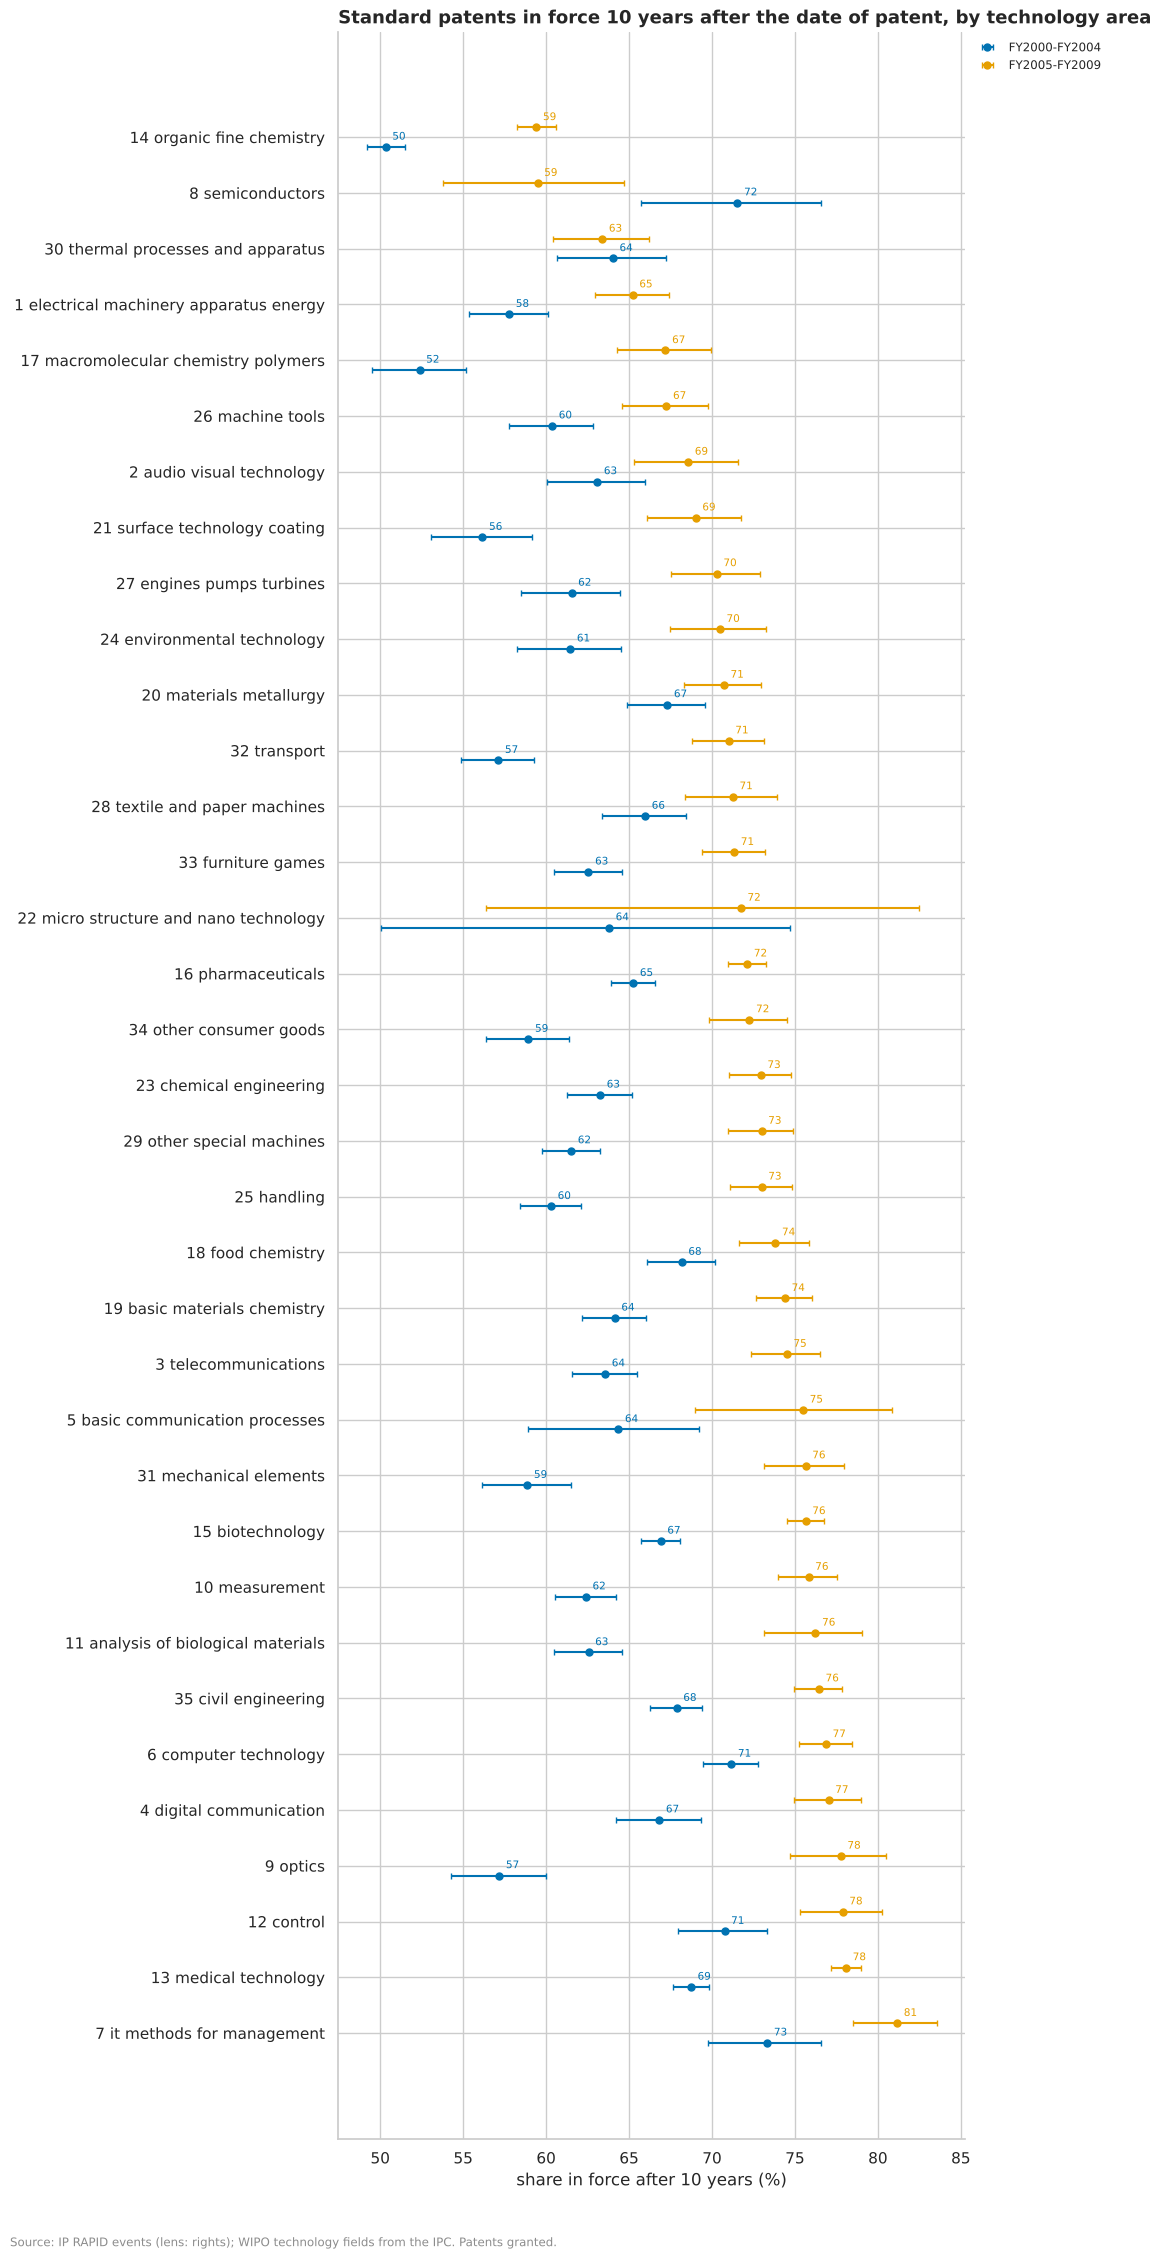

In [11]:
# By technology area (WIPO's 35 fields): the share in force after 10 years, for both periods, and whether the order of
# the fields holds from one period to the other
km_area = lifetimes("patent_type = 'standard' AND main_area IS NOT NULL", "main_area", [(2005, 2009), (2000, 2004)])
area10 = at_years(km_area, [10]).droplevel("years")
wide = area10["in force"].unstack("period")
order = wide.sort_values("FY2005-FY2009").index
plot = area10.reset_index().set_index("group").loc[order].rename(columns={"in force": "share"})
plot.index = plot.index.str.replace("_", " ")
fig = bi.dot_chart(
    plot,
    value="share",
    low="low",
    high="high",
    hue="period",
    fmt="{:.0f}",
    title="Standard patents in force 10 years after the date of patent, by technology area",
    xlabel="share in force after 10 years",
)
style.source(fig, "IP RAPID events (lens: rights); WIPO technology fields from the IPC. Patents granted.")
print(
    "Fields:",
    len(wide.dropna()),
    "; agreement of the two periods' order (Spearman rho):",
    round(wide.dropna().corr(method="spearman").iloc[0, 1], 3),
)
print(
    "Range across fields, FY2005-FY2009:",
    f"{100 * wide['FY2005-FY2009'].min():.1f}% to {100 * wide['FY2005-FY2009'].max():.1f}%",
)

# Does the origin gap hold within fields? Australian against overseas organisations, field by field (FY2005-FY2009)
km_af = lifetimes(
    STD + " AND founder_type = 'organisation' AND main_area IS NOT NULL",
    "main_area || ' / ' || CASE WHEN founding_australian THEN 'AU' ELSE 'overseas' END",
    [(2005, 2009)],
)
af = bi.survival_with_interval(km_af, 10, by="key").reset_index()
af[["area", "who"]] = af.key.str.split(" | ", regex=False).str[0].str.split(" / ", expand=True)
both = af.pivot(index="area", columns="who", values="in force").dropna()
gap = 100 * (both["AU"] - both["overseas"])
print(
    f"Fields with both (30 or more at risk at 10 years): {len(both)};",
    f"Australian organisations lower in {(gap < 0).sum()};",
    f"median gap {gap.median():.1f} points (range {gap.min():.1f} to {gap.max():.1f})",
)

In [12]:
# Trade marks: in force after 10 years (the first renewal), filed FY2010 to FY2015 against FY2003 to FY2009; designs:
# in force after 5 years (the one renewal under the Designs Act 2003), filed FY2010 to FY2019 against FY2005 to FY2009;
# by who filed them and, for Australian filers, by representation
TM = "ip_right_type = 'trade_mark' AND founding_australian IS NOT NULL AND founder_type IS NOT NULL"
DS = "ip_right_type = 'design' AND founding_australian IS NOT NULL AND founder_type IS NOT NULL"
tm_life = at_years(lifetimes(TM, "@FILER", [(2010, 2015), (2003, 2009)]), [10])
tm_rep = at_years(
    lifetimes(
        TM + " AND founding_australian AND representation IS NOT NULL",
        "'Australian, ' || representation",
        [(2010, 2015), (2003, 2009)],
    ),
    [10],
)
ds_life = at_years(lifetimes(DS, "@FILER", [(2010, 2019), (2005, 2009)]), [5])
ds_rep = at_years(
    lifetimes(
        DS + " AND founding_australian AND representation IS NOT NULL",
        "'Australian, ' || representation",
        [(2010, 2019), (2005, 2009)],
    ),
    [5],
)
for name, t in (
    ("Trade marks, after 10 years", pd.concat([tm_life, tm_rep])),
    ("Designs, after 5 years", pd.concat([ds_life, ds_rep])),
):
    print(name)
    display((100 * t[["in force", "low", "high"]]).round(1).join(t["at risk"]).droplevel("years").unstack("period"))

Trade marks, after 10 years


in force                         low                        high                     at risk              
period                   FY2003-FY2009 FY2010-FY2015 FY2003-FY2009 FY2010-FY2015 FY2003-FY2009 FY2010-FY2015 FY2003-FY2009 FY2010-FY2015
group                                                                                                                                   
Australian individuals            27.7            26          27.3          25.5          28.1          26.4       3.8e+04     3.405e+04
Australian organisations          44.6          45.9          44.4          45.6          44.9          46.2     1.213e+05     1.123e+05
Australian, attorney              52.1            52          51.7          51.6          52.4          52.3     7.571e+04     7.625e+04
Australian, other_agent           30.3          34.6          29.6          33.7          30.9          35.5      1.86e+04     1.158e+04
Australian, self                  30.2          28.6          29.9          28.3          30.6            29     6.495e+04     5.849e+04
overseas individuals              40.6            38          39.4          36.5          41.9          39.5         5,491         3,940
overseas organisations            56.3          56.3            56            56          56.6          56.6     9.976e+04     1.047e+05

Designs, after 5 years


in force                         low                        high                     at risk              
period                   FY2005-FY2009 FY2010-FY2019 FY2005-FY2009 FY2010-FY2019 FY2005-FY2009 FY2010-FY2019 FY2005-FY2009 FY2010-FY2019
group                                                                                                                                   
Australian individuals            27.1          28.3          25.6          27.2          28.6          29.5         3,433         5,732
Australian organisations          46.4          44.4          45.4          43.7          47.5          45.1         8,426       1.8e+04
Australian, attorney              50.8          47.2          49.6          46.4          51.9          47.9         7,024     1.599e+04
Australian, other_agent           24.9          22.2          23.4          20.6          26.5          23.7         2,865         2,647
Australian, self                  28.8          28.9          26.9          27.7          30.8          30.1         1,970         5,089
overseas individuals              36.9            40          33.8            38            40            42           917         2,151
overseas organisations            62.1          69.9          61.3          69.4          62.9          70.3     1.356e+04      3.59e+04

#### Observations
**B8 (observational). Australian organisations keep their standard patents longer than overseas organisations do;
individuals, Australian or not, keep them least.** Share of granted standard patents still in force (95% interval):
- **After 10 years:** Australian organisations 78.7% (77.5% to 79.9%) for FY2005 to FY2009 filings and 72.8% (71.5% to
  74.1%) for FY2000 to FY2004; overseas organisations 72.3% (71.9% to 72.6%) and 62.9% (62.5% to 63.3%); Australian
  individuals 66.4% and 55.3%; overseas individuals 68.6% and 55.4%.
- **After 15 years:** Australian organisations 50.3% and 42.4%; overseas organisations 43.9% and 36.8%.
- **Within technology:** in 32 fields with enough patents, Australian organisations keep a higher share to 10 years
  than overseas organisations in all but 9, by a median 4.7 points (from -15.8 to 28.6): the gap is not only a
  matter of which fields Australians patent in.
- **Third factors:** selection at grant (Australians' applications are granted less often, B6, so their granted
  patents may be the stronger ones), family reach (an Australian-only patent has one set of fees, B10), and firm size.
  Every cohort lengthened its patents' lives in the later period, in line with U36.

**B9 (descriptive). Technology areas differ in how long their patents are kept, but the order is only moderately
stable.** Share in force after 10 years, FY2005 to FY2009, from 59.4% to 81.2% across the 35 fields (chart above). The
fields' order agrees between the two periods with a Spearman rho of 0.459: a weak replication, so field differences in
lifetimes are kept as a lead only together with B8.

**B10 (observational). Trade marks and designs: overseas organisations renew most, Australian individuals least, and
Australians who file alone renew far less.**
- **Trade marks in force after 10 years** (filed FY2010 to FY2015; FY2003 to FY2009): overseas organisations 56.3%
  (56.3%), Australian organisations 45.9% (44.6%), overseas individuals 38.0% (40.6%), Australian individuals 26.0%
  (27.7%). Among Australian filers: with an attorney 52.0% (52.1%), through another agent 34.6% (30.3%), alone 28.6%
  (30.2%).
- **Designs in force after 5 years** (filed FY2010 to FY2019; FY2005 to FY2009): overseas organisations 69.9% (62.1%),
  Australian organisations 44.4% (46.4%), Australian individuals 28.3% (27.1%); Australians with an attorney 47.2%
  (50.8%), alone 28.9% (28.8%).
- Every interval is within about 1 point. The differences hold in both periods. **Third factors:** applicant type
  (individuals file alone most, B5) and the survival of the business behind a mark, which these data do not hold.

### 1.3 Family reach and citations, by origin, applicant type and technology

**From:** U93, U94. **Informs:** Q1. A patent's family reach (the offices it is filed in) is chosen and paid for by its
owner; the families citing it within five years are a sign of its influence. Citations are compared as **percentile
ranks within their technology field and year of filing** (50 is the typical patent of its field and year), because
they vary so much by field and age, and beside family reach, because a family filed in more offices is more often
cited. Standard patents filed FY2010 to FY2019, against FY2000 to FY2009.

In [13]:
reach = (
    rsql("""
    SELECT @PERIOD AS period, @FILER AS filer, count(*) AS patents, median(family_offices) AS "median offices",
           count(*) FILTER (family_offices = 1) AS only_au, count(*) FILTER (family_offices >= 5) AS five_plus,
           count(*) FILTER (family_granted_us) AS us
    FROM {lens/rights}
    WHERE patent_type = 'standard' AND filing_fy BETWEEN 2000 AND 2019 AND family_offices IS NOT NULL
      AND founding_australian IS NOT NULL AND founder_type IS NOT NULL
    GROUP BY ALL
""")
    .set_index(["filer", "period"])
    .sort_index()
)
for col, name in (
    ("only_au", "filed only in Australia (%)"),
    ("five_plus", "five or more offices (%)"),
    ("us", "granted in the US (%)"),
):
    lo, hi = bi.wilson(reach[col], reach.patents)
    reach[name] = 100 * reach[col] / reach.patents
    reach[name + " interval"] = [f"{100 * a:.1f} to {100 * b:.1f}" for a, b in zip(lo, hi, strict=True)]
reach.drop(columns=["only_au", "five_plus", "us"]).round(2).unstack("period").T

filer                                              Australian individuals Australian organisations overseas individuals overseas organisations
                                     period                                                                                                   
patents                              FY2000-FY2009                   7310                    15658                14796                 186575
                                     FY2010-FY2019                   5662                    18991                14353                 234524
median offices                       FY2000-FY2009                      1                        1                    5                      7
                                     FY2010-FY2019                      1                        2                    5                      6
filed only in Australia (%)          FY2000-FY2009                  87.31                    73.02                11.11                   7.34
                                     FY2010-FY2019                  59.91                    40.71                 8.66                   8.23
filed only in Australia (%) interval FY2000-FY2009           86.5 to 88.0             72.3 to 73.7         10.6 to 11.6             7.2 to 7.5
                                     FY2010-FY2019           58.6 to 61.2             40.0 to 41.4           8.2 to 9.1             8.1 to 8.3
five or more offices (%)             FY2000-FY2009                   4.21                    13.07                59.96                  72.35
                                     FY2010-FY2019                  10.28                     22.6                58.53                  69.58
five or more offices (%) interval    FY2000-FY2009             3.8 to 4.7             12.5 to 13.6         59.2 to 60.7           72.1 to 72.6
                                     FY2010-FY2019            9.5 to 11.1             22.0 to 23.2         57.7 to 59.3           69.4 to 69.8
granted in the US (%)                FY2000-FY2009                   5.98                    15.79                55.19                  61.93
                                     FY2010-FY2019                  18.77                     32.8                 59.1                  67.13
granted in the US (%) interval       FY2000-FY2009             5.5 to 6.5             15.2 to 16.4         54.4 to 56.0           61.7 to 62.2
                                     FY2010-FY2019           17.8 to 19.8             32.1 to 33.5         58.3 to 59.9           66.9 to 67.3

Mean citation percentile within field and year, all reach (50 = typical):


period,FY2000-FY2009,FY2010-FY2019
filer,,
Australian individuals,20.3,24.1
Australian organisations,25,32.2
overseas individuals,46.3,46
overseas organisations,53.6,52.3


patents               mean percentile              
period                                     FY2000-FY2009 FY2010-FY2019   FY2000-FY2009 FY2010-FY2019
reach             filer                                                                             
1 office          Australian individuals            6382          3391            17.1            14
                  Australian organisations         11433          7732              16          15.2
                  overseas individuals              1663          1243            15.7          13.1
                  overseas organisations           13732         19307            12.6          11.6
2 to 4 offices    Australian individuals             620          1688            39.4          36.2
                  Australian organisations          2179          6967              42          39.9
                  overseas individuals              4287          4709            46.1          44.7
                  overseas organisations           37921         52035            52.1          50.7
5 or more offices Australian individuals             308           582            47.7          48.3
                  Australian organisations          2046          4292            57.6          50.6
                  overseas individuals              8882          8401              52          51.6
                  overseas organisations          135107        163182            58.2          57.7

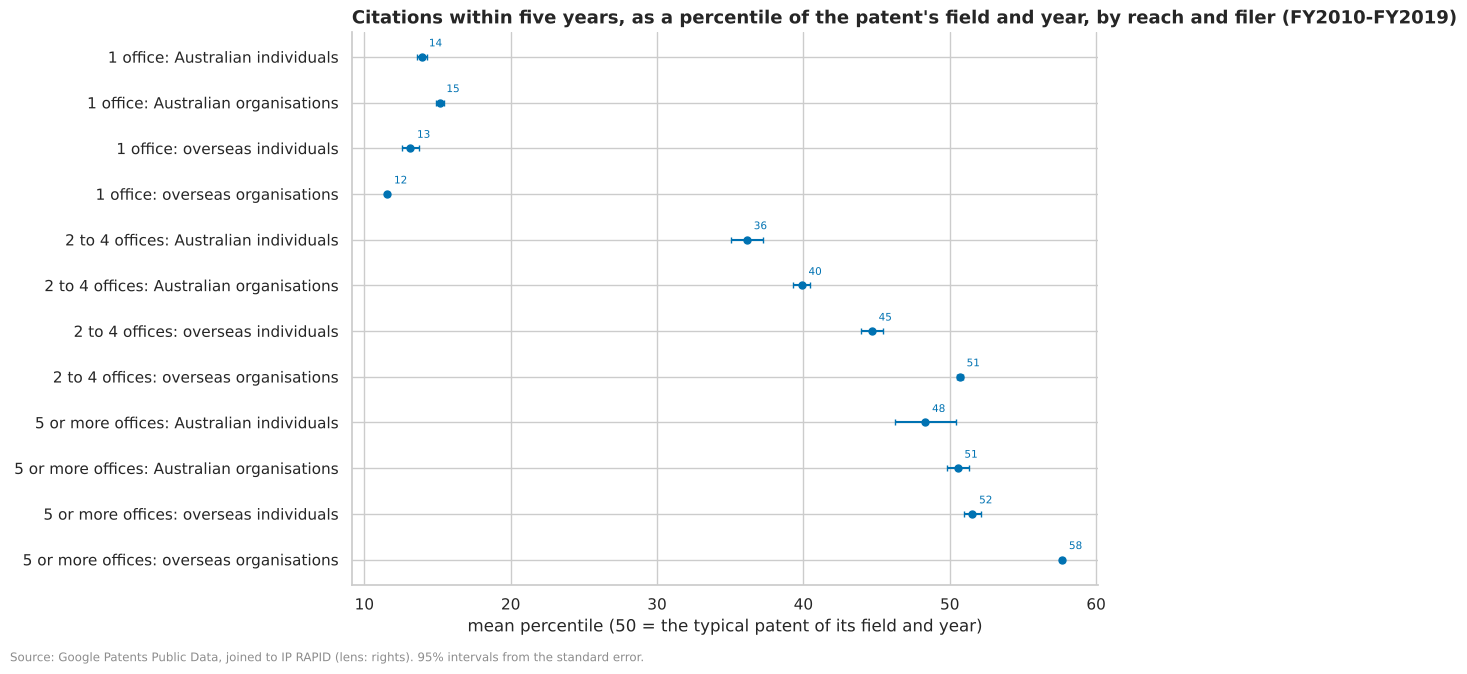

In [14]:
cites = rsql("""
    WITH c AS (
        SELECT @PERIOD AS period, @FILER AS filer, family_offices, main_area,
               100 * (percent_rank() OVER w + cume_dist() OVER w) / 2 AS pct
        FROM {lens/rights}
        WHERE patent_type = 'standard' AND filing_fy BETWEEN 2000 AND 2019 AND family_citations_5y IS NOT NULL
          AND main_area IS NOT NULL
        WINDOW w AS (PARTITION BY filing_fy, main_area ORDER BY family_citations_5y))
    SELECT period, filer,
           CASE WHEN family_offices = 1 THEN '1 office' WHEN family_offices < 5 THEN '2 to 4 offices'
                ELSE '5 or more offices' END AS reach,
           count(*) AS patents, avg(pct) AS "mean percentile", stddev(pct) / sqrt(count(*)) AS se
    FROM c WHERE filer IS NOT NULL GROUP BY ALL
""")
allr = cites.assign(w=cites.patents * cites["mean percentile"]).groupby(["filer", "period"])[["w", "patents"]].sum()
allr["mean percentile"] = allr.w / allr.patents
print("Mean citation percentile within field and year, all reach (50 = typical):")
display(allr["mean percentile"].round(1).unstack("period"))
cites["low"] = cites["mean percentile"] - 1.96 * cites.se
cites["high"] = cites["mean percentile"] + 1.96 * cites.se
plot = cites[cites.period == "FY2010-FY2019"].sort_values(["reach", "filer"])
plot.index = plot.reach + ": " + plot.filer
fig = bi.dot_chart(
    plot,
    value="mean percentile",
    low="low",
    high="high",
    percent=False,
    fmt="{:.0f}",
    title="Citations within five years, as a percentile of the patent's field and year, "
    "by reach and filer (FY2010-FY2019)",
    xlabel="mean percentile (50 = the typical patent of its field and year)",
)
style.source(
    fig, "Google Patents Public Data, joined to IP RAPID (lens: rights). 95% intervals from the standard error."
)
cites.set_index(["reach", "filer", "period"])[["patents", "mean percentile"]].round(1).unstack("period")

#### Observations
**B11 (observational). Australian organisations' patents reach fewer countries than overseas filers', though the gap
has narrowed.** Standard patents, FY2010 to FY2019 (FY2000 to FY2009):
- **Filed only in Australia:** Australian organisations 40.71% (73.02%), Australian individuals 59.91% (87.31%),
  overseas organisations 8.23% (7.34%), each within about a point.
- **Five or more offices:** Australian organisations 22.6% (13.07%), overseas organisations 69.58% (72.35%).
- **Granted in the United States:** Australian organisations 32.8% (15.79%), overseas organisations 67.13% (61.93%).
- The gap holds in both decades, but Australian organisations' share filed only here fell from 73.02% to 40.71%. Whether that
  is a change in practice or in how fully Google Patents holds older Australian-only families is not shown here (a
  lead).

**B12 (observational). Australians' patents are cited less within their field and year, and most of the gap goes
with family reach.** Mean percentile of citations within five years, within field and year (50 = typical):
- **All reach:** overseas organisations 52.3 (FY2010 to FY2019) and 53.6 (FY2000 to FY2009); Australian organisations
  32.2 and 25.0; Australian individuals 24.1 and 20.3.
- **Within the same reach** the gap shrinks or reverses: among patents filed in one office, Australian organisations
  15.2 against overseas organisations' 11.6 (16.0 against 12.6); in five or more offices, 50.6 against 57.7 (57.6
  against 58.2). Among those filed in 2 to 4 offices, 39.9 against 50.7 (42.0 against 52.1).
- So reach is the main third factor: a narrow family is seldom cited wherever it comes from. Since owners choose and
  pay for reach, citations and reach are two readings of the same expected value, not independent evidence of it.

### 1.4 Expedited examination and years in force

**From:** U34, U36, and the commissioned study IP Australia cites (ADR 0024), which found expedited patents kept
longer. **Informs:** Q1, Q4. Does asking for speed go with keeping the right longer? Standard patents whose examination
was requested, filed FY2010 to FY2016 against FY2003 to FY2009; trade marks without a priority claim (whose recorded
expedites are applicants' requests, U103), filed FY2010 to FY2015 against FY2003 to FY2009, before November 2018's
change of records.

In [15]:
EXP = "CASE WHEN exam_expedited THEN 'expedited' ELSE 'not expedited' END"
share = rsql("""
    SELECT coalesce(patent_type, ip_right_type) AS t,
           CASE WHEN filing_fy >= 2010 THEN 'FY2010 on' ELSE 'FY2003-FY2009' END AS period, @FILER AS filer,
           count(*) AS n, count(*) FILTER (exam_expedited) AS expedited,
           count(*) FILTER (registered_date IS NOT NULL) AS granted,
           count(*) FILTER (exam_expedited AND registered_date IS NOT NULL) AS expedited_granted
    FROM {lens/rights}
    WHERE (patent_type = 'standard' AND filing_fy BETWEEN 2003 AND 2016 AND exam_requested_date IS NOT NULL
           OR ip_right_type = 'trade_mark' AND filing_fy BETWEEN 2003 AND 2015 AND coalesce(priority_claims, 0) = 0)
      AND exam_expedited IS NOT NULL AND founding_australian IS NOT NULL AND founder_type IS NOT NULL
    GROUP BY ALL
""")
s = share.groupby(["t", "period", "filer"])[["expedited", "n", "granted", "expedited_granted"]].sum()
s["expedited (%)"] = 100 * s.expedited / s.n
s["granted if expedited (%)"] = 100 * s.expedited_granted / s.expedited
s["granted if not (%)"] = 100 * (s.granted - s.expedited_granted) / (s.n - s.expedited)
s[["n", "expedited", "expedited (%)", "granted if expedited (%)", "granted if not (%)"]].round(2)

n  expedited  expedited (%)  granted if expedited (%)  granted if not (%)
t          period        filer                                                                                                   
standard   FY2003-FY2009 Australian individuals      3703        728          19.66                     71.29               48.27
                         Australian organisations   10251        914           8.92                     79.87               63.46
                         overseas individuals        9399        179            1.9                     79.33               62.94
                         overseas organisations    118785        999           0.84                     88.89               70.77
           FY2010 on     Australian individuals      2844        566           19.9                     66.78                  45
                         Australian organisations   10972       1851          16.87                     69.75                  57
                         overseas individuals        8549        704           8.23                     81.68                66.2
                         overseas organisations    143018      11448              8                     82.53               76.18
trade_mark FY2003-FY2009 Australian individuals     71437       4981           6.97                     63.54               53.17
                         Australian organisations  185536      16557           8.92                     73.32               65.31
                         overseas individuals        4735        107           2.26                      75.7               79.45
                         overseas organisations     72848       1531            2.1                     82.56               86.41
           FY2010 on     Australian individuals     67523       2841           4.21                     64.59               50.59
                         Australian organisations  177260      13650            7.7                     74.37               63.02
                         overseas individuals        3871         72           1.86                     69.44               75.18
                         overseas organisations     74267       1532           2.06                     83.22               85.05

In [16]:
km_exp = lifetimes(
    STD + " AND exam_requested_date IS NOT NULL AND exam_expedited IS NOT NULL",
    EXP + " || ', ' || @FILER",
    [(2010, 2016), (2003, 2009)],
)
std_exp = at_years(km_exp, [5, 10])
km_exp_all = lifetimes(
    "patent_type = 'standard' AND exam_requested_date IS NOT NULL AND exam_expedited IS NOT NULL",
    EXP,
    [(2010, 2016), (2003, 2009)],
)
std_exp_all = at_years(km_exp_all, [5, 10])
km_tm = lifetimes(
    TM + " AND coalesce(priority_claims, 0) = 0 AND exam_expedited IS NOT NULL",
    EXP + " || ', ' || @FILER",
    [(2010, 2015), (2003, 2009)],
)
tm_exp = at_years(km_tm, [10])
for name, t in (
    ("Standard patents, all filers", std_exp_all),
    ("Standard patents, by filer", std_exp),
    ("Trade marks without a priority claim, by filer", tm_exp),
):
    print(name)
    display((100 * t[["in force", "low", "high"]]).round(1).join(t["at risk"]).unstack("period"))

Standard patents, all filers


in force                         low                        high                     at risk              
period              FY2003-FY2009 FY2010-FY2016 FY2003-FY2009 FY2010-FY2016 FY2003-FY2009 FY2010-FY2016 FY2003-FY2009 FY2010-FY2016
group         years                                                                                                                
expedited     5              99.3          97.3          98.8            97          99.5          97.6         2,265     1.138e+04
              10             68.7          76.8          66.8            76          70.6          77.5         1,572         8,979
not expedited 5               100          98.1          99.9            98           100          98.2     9.651e+04     1.095e+05
              10             71.3          68.7          71.1          68.5          71.6            69     6.887e+04     7.675e+04

Standard patents, by filer


in force                         low                        high                     at risk              
period                                        FY2003-FY2009 FY2010-FY2016 FY2003-FY2009 FY2010-FY2016 FY2003-FY2009 FY2010-FY2016 FY2003-FY2009 FY2010-FY2016
group                                   years                                                                                                                
expedited, Australian individuals       5              98.1          88.4          96.4          84.7            99          91.2           510           337
                                        10             54.1          64.6          49.8          59.5          58.3          69.1           308           245
expedited, Australian organisations     5              99.7          96.4          98.9          95.3          99.9          97.3           730         1,250
                                        10             69.9          80.2          66.4          77.9          73.1          82.2           512         1,044
expedited, overseas individuals         5              97.2          95.3          92.7          93.2          98.9          96.8           141           549
                                        10             55.6          66.8          47.1          62.8          63.4          70.5            80           390
expedited, overseas organisations       5              99.9          97.9          99.2          97.6           100          98.2           888         9,264
                                        10             78.5          77.4          75.6          76.6          81.1          78.3           698         7,316
not expedited, Australian individuals   5              99.8          97.6          99.4          96.4          99.9          98.3         1,434         1,002
                                        10             68.8          70.7          66.3          67.8          71.1          73.4           989           735
not expedited, Australian organisations 5               100          98.8          99.9          98.5           100          99.1         5,925         5,138
                                        10             79.1            77            78          75.8          80.1          78.1         4,686         4,002
not expedited, overseas individuals     5              99.9          98.1          99.8          97.7           100          98.5         5,803         5,100
                                        10             67.1          65.8          65.9          64.5          68.3          67.1         3,896         3,423
not expedited, overseas organisations   5               100          98.1           100            98           100          98.2     8.334e+04     9.831e+04
                                        10             71.1          68.4          70.8          68.2          71.4          68.7     5.929e+04     6.861e+04

Trade marks without a priority claim, by filer


in force                         low                        high                     at risk              
period                                        FY2003-FY2009 FY2010-FY2015 FY2003-FY2009 FY2010-FY2015 FY2003-FY2009 FY2010-FY2015 FY2003-FY2009 FY2010-FY2015
group                                   years                                                                                                                
expedited, Australian individuals       10             30.1          28.8          28.5          26.7          31.7          30.9         3,118         1,797
expedited, Australian organisations     10             45.6          49.8          44.7          48.8          46.5          50.8     1.194e+04         9,986
expedited, overseas individuals         10             39.5            32          28.9          19.7          49.9            45            79            49
expedited, overseas organisations       10             57.7          59.2          54.9          56.5          60.3          61.9         1,251         1,255
not expedited, Australian individuals   10             27.5          25.8            27          25.3            28          26.3     3.484e+04      3.22e+04
not expedited, Australian organisations 10             44.5          45.5          44.2          45.2          44.8          45.8      1.09e+05     1.018e+05
not expedited, overseas individuals     10             42.9          40.1          41.3          38.3          44.5          41.8         3,500         2,720
not expedited, overseas organisations   10             60.6          60.3          60.2          59.9            61          60.6     5.972e+04     5.972e+04

#### Observations
**B13 (observational). Expedited standard patents last longer in the later period but not the earlier one; the
pooled link is a composition effect, and it holds only for overseas organisations.**
- **Pooled:** expedited patents in force after 10 years 76.8% (76.0% to 77.5%) against 68.7% (68.5% to 69.0%) for
  FY2010 to FY2016 filings, but 68.7% against 71.3% for FY2003 to FY2009: the association does not replicate.
- **By filer:** overseas organisations 77.4% against 68.4% (FY2010 to FY2016) and 78.5% against 71.1% (FY2003 to
  FY2009), higher in both; Australian organisations 80.2% against 77.0%, then 69.9% against 79.1%;
  Australian individuals 64.6% against 70.7%, then 54.1% against 68.8% (expedited patents kept less).
- **Who asks changed:** 0.84% of overseas organisations' examined patents were expedited in FY2003 to FY2009 and 8.0%
  from FY2010; Australian individuals 19.66% and 19.9%. As overseas organisations, who keep patents longer, became most
  of the expedited, the pooled figure rose: Simpson's paradox.
- **Expedited applications are granted more often** in every group: for example Australian organisations 69.75%
  against 57.0%, overseas organisations 82.53% against 76.18% (FY2010 on).
- IP Australia's commissioned study found expedited patents kept longer (ADR 0024); here that holds for overseas
  organisations only. Third factors: the filer (above), the urgency behind a request (a product on the market, a
  dispute), which the data do not record.

**B14 (descriptive). Trade marks: expediting goes with renewal only slightly, and not for overseas organisations: not
a lead.** Marks without a priority claim, in force after 10 years (FY2010 to FY2015; FY2003 to FY2009), expedited
against not: Australian organisations 49.8% against 45.5% (45.6% against 44.5%), Australian individuals 28.8% against
25.8% (30.1% against 27.5%), overseas organisations 59.2% against 60.3% (57.7% against 60.6%). Differences of 1 to 4
points for Australians, below the size this stage looks for.

### 1.5 The route into Australia, and where inventions are made against who files them

**From:** U90, U96. **Informs:** Q1, Q2. Standard patents filed FY2010 to FY2019 against FY2000 to FY2009.

filing_route                            pct  convention  australian_priority  divisional  direct
filer                    period                                                                 
Australian individuals   FY2000-FY2009 27.5           1                 39.7         6.7      25
                         FY2010-FY2019 29.2         1.8                   31        10.2    27.8
Australian organisations FY2000-FY2009 51.4         1.7                   28        11.6     7.3
                         FY2010-FY2019 45.3           2                   21        22.4     9.2
overseas individuals     FY2000-FY2009   79        10.7                  0.3         5.1       5
                         FY2010-FY2019 79.9         7.8                  0.2         9.7     2.5
overseas organisations   FY2000-FY2009 78.2        13.4                  0.5         7.1     0.8
                         FY2010-FY2019 74.7         8.9                  0.1        15.6     0.6

Screen strength of filer type x route: {'strength': 0.243, 'strength (replication)': 0.29}


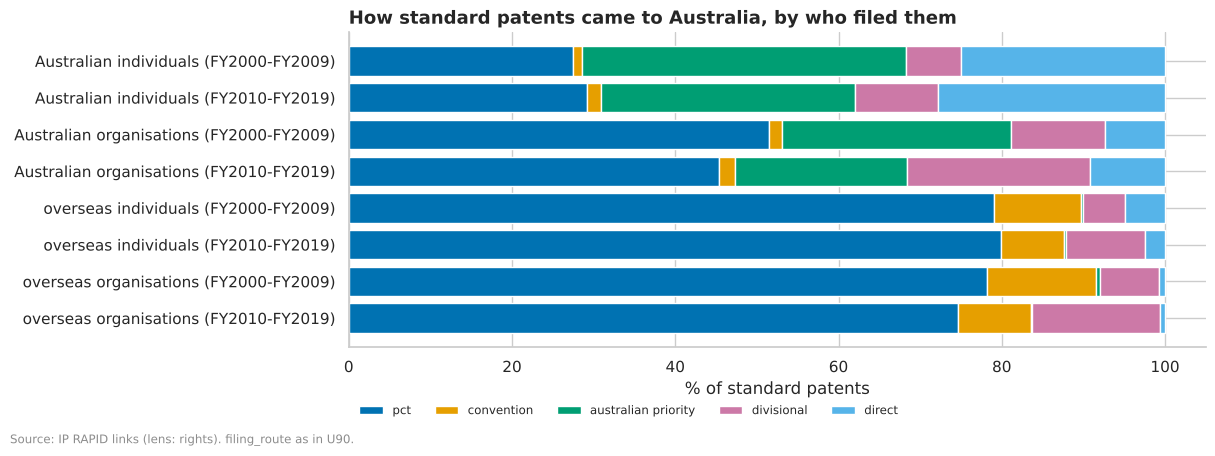

In [17]:
route = rsql("""
    SELECT @PERIOD AS period, @FILER AS filer, filing_route, count(*) AS n
    FROM {lens/rights}
    WHERE patent_type = 'standard' AND filing_fy BETWEEN 2000 AND 2019 AND filing_route IS NOT NULL
      AND founding_australian IS NOT NULL AND founder_type IS NOT NULL
    GROUP BY ALL
""")
shares = route.pivot_table(index=["filer", "period"], columns="filing_route", values="n", aggfunc="sum").fillna(0)
shares = 100 * shares.div(shares.sum(axis=1), axis=0)
order = ["pct", "convention", "australian_priority", "divisional", "direct"]
shares = shares[[c for c in order if c in shares] + [c for c in shares if c not in order]]
fig, ax = plt.subplots(figsize=(12, 4.2))
left = np.zeros(len(shares))
labels = [f"{f} ({p})" for f, p in shares.index]
for i, c in enumerate(shares.columns):
    ax.barh(labels, shares[c], left=left, color=style.PALETTE[i], label=c.replace("_", " "))
    left += shares[c].to_numpy()
ax.invert_yaxis()
ax.set_xlabel("% of standard patents")
ax.legend(frameon=False, fontsize=8.5, ncol=5, loc="upper left", bbox_to_anchor=(0, -0.15))
ax.set_title("How standard patents came to Australia, by who filed them")
style.source(fig, "IP RAPID links (lens: rights). filing_route as in U90.")
display(shares.round(1))
s = rights_screen["standard"]["verdicts"].set_index(["variable 1", "variable 2"])
print(
    "Screen strength of filer type x route:",
    s.loc[("applicant_type", "filing_route"), ["strength", "strength (replication)"]].round(3).to_dict(),
)

In [18]:
made = (
    rsql("""
    SELECT @PERIOD AS period, founding_australian AS filed_from_au, invented_in_australia AS made_in_au, count(*) AS n
    FROM {lens/rights}
    WHERE patent_type = 'standard' AND filing_fy BETWEEN 2000 AND 2019 AND founding_australian IS NOT NULL
      AND invented_in_australia IS NOT NULL
    GROUP BY ALL
""")
    .set_index(["period", "filed_from_au", "made_in_au"])
    .n
)
rows = {}
for p in ("FY2000-FY2009", "FY2010-FY2019"):
    m = made.loc[p]
    here = m.xs(True, level="made_in_au")
    rows[p] = {
        "inventions made in Australia (an inventor here)": int(here.sum()),
        "... filed from overseas": int(here.loc[False]),
        "... share filed from overseas (%)": 100 * here.loc[False] / here.sum(),
        "filed from Australia, no inventor here": int(m.loc[(True, False)]),
        "filed from Australia: share made here (%)": 100 * m.loc[(True, True)] / m.loc[True].sum(),
    }
    lo, hi = bi.wilson(np.array([here.loc[False]]), np.array([here.sum()]))
    rows[p]["... interval (%)"] = f"{100 * lo[0]:.2f} to {100 * hi[0]:.2f}"
pd.DataFrame(rows).T.round(2)

,inventions made in Australia (an inventor here),... filed from overseas,... share filed from overseas (%),"filed from Australia, no inventor here",filed from Australia: share made here (%),... interval (%)
FY2000-FY2009,6142,1184,19.28,509,90.69,18.31 to 20.28
FY2010-FY2019,16193,2349,14.51,771,94.72,13.97 to 15.06


#### Observations
**B15 (descriptive). Each kind of filer has its own route into Australia, and divisionals doubled.** Standard patents,
FY2010 to FY2019 (FY2000 to FY2009):
- **Overseas organisations:** the PCT 74.7% (78.2%), a priority abroad 8.9% (13.4%), divisionals 15.6% (7.1%).
- **Australian organisations:** the PCT 45.3% (51.4%), claiming an Australian application 21.0% (28.0%), divisionals
  22.4% (11.6%), direct 9.2% (7.3%).
- **Australian individuals:** claiming an Australian application 31.0% (39.7%), the PCT 29.2% (27.5%), direct 27.8%
  (25.0%).
- The screen's strength of applicant type × route: 0.243 and 0.29. The rise of divisionals among both Australian and
  overseas organisations is a lead for Stage 3 (a divisional keeps an application pending longer).

**B16 (descriptive). About one patent in seven made in Australia is filed by an overseas applicant.** Of the standard
patents with an inventor in Australia, 14.51% were filed from overseas in FY2010 to FY2019 (2,349 of 16,193; interval
13.97% to 15.06%) and 19.28% in FY2000 to FY2009 (1,184 of 6,142). Patents filed from Australia have an inventor here
94.72% and 90.69% of the time (771 and 509 without one). These count patents whose inventors' countries are known
(U95); Australian inventions filed only abroad are not in IP RAPID at all (the review's F07).

### 1.6 Women among inventors, by field and filer (the gender analysis)

**From:** U97, U98, U107. **Informs:** Q2. Estimated from first names (WIPO's World Gender-Name Dictionary), so these
are expected counts for groups, never anyone's recorded gender, and read only for inventors in Australia, the one
country whose estimates WIPO's published shares confirm (U97). Intervals come from a bootstrap that resamples whole
patents.

**Standard patents** (Google Patents' inventors whose country is Australia, as U98): by who filed and by technology,
filed FY2010 to FY2019 against FY2000 to FY2009. **Provisional applications** (IP Australia's register, ADR 0029):
by who filed and by the filer's state, FY2013 to FY2022 against FY2003 to FY2012, with each year's coverage shown
(U106; OQ17 asks why fewer name inventors since FY2024).

Patents: 22,335; inventor places in Australia: 44,251; with an estimate: 93.38%


ratio                         low                        high                        rows                       total  \
period                   FY2000-FY2009 FY2010-FY2019 FY2000-FY2009 FY2010-FY2019 FY2000-FY2009 FY2010-FY2019 FY2000-FY2009 FY2010-FY2019 FY2000-FY2009   
filer                                                                                                                                                    
Australian individuals           11.55         11.21          9.69           9.9         13.47         12.63         1,010         2,517         1,249   
Australian organisations         15.85         12.17         14.99         11.78         16.74         12.62         3,948     1.133e+04         8,175   
overseas individuals              5.56         10.16             0          0.01         16.81         23.84            18            23            18   
overseas organisations            9.83         10.57          8.44          9.46         11.29         11.51         1,166         2,326         1,864   

                                        
period                   FY2010-FY2019  
filer                                   
Australian individuals           3,087  
Australian organisations     2.294e+04  
overseas individuals                22  
overseas organisations           3,970

Fields in both periods: 12 ; agreement of their order (Spearman rho): 0.86


period,FY2000-FY2009,FY2010-FY2019
main_area,,
35_civil_engineering,4.3,4.2
32_transport,4.1,5.2
29_other_special_machines,9.6,5.7
10_measurement,5.8,7.2
20_materials_metallurgy,12.2,11.2
6_computer_technology,15.3,11.3
13_medical_technology,9.6,12.1
33_furniture_games,12.2,12.7
28_textile_and_paper_machines,39.7,15.9


FY2010-FY2019 range: 4.2% (35_civil_engineering) to 26.9% (15_biotechnology)


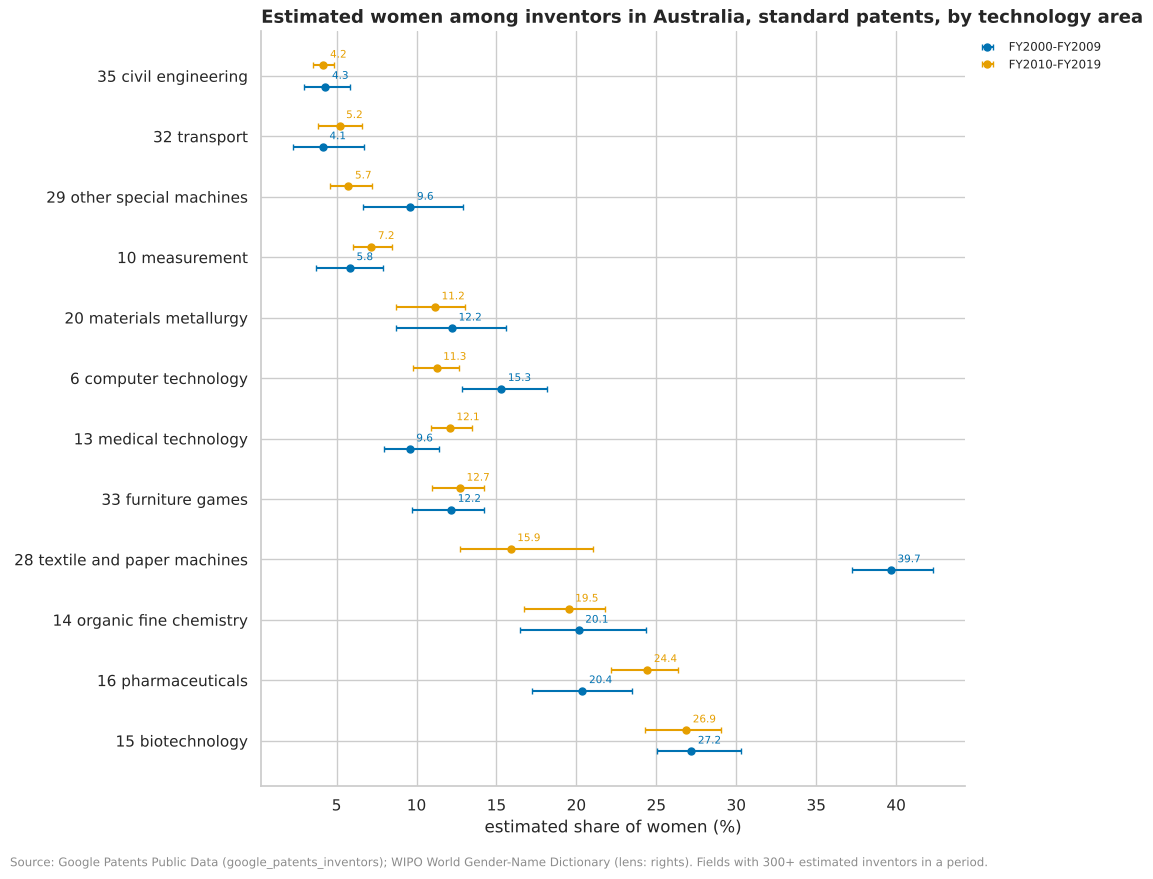

In [19]:
inv = rsql(
    """
    SELECT r.application_number, @PERIOD AS period, @FILER AS filer, r.main_area,
           sum(i.p_female) AS women, count(i.p_female) AS estimated, count(*) AS places
    FROM {lens/rights} r JOIN {google_patents_inventors/inventors} i USING (family_id)
    WHERE r.patent_type = 'standard' AND r.filing_fy BETWEEN 2000 AND 2019 AND i.country_code = 'AU'
      AND r.founding_australian IS NOT NULL AND r.founder_type IS NOT NULL
    GROUP BY ALL
""",
    max_rows=None,
)
print(
    f"Patents: {len(inv):,}; inventor places in Australia: {inv.places.sum():,};",
    f"with an estimate: {100 * inv.estimated.sum() / inv.places.sum():.2f}%",
)
by_filer = bi.ratio_by(inv, ["filer", "period"], "women", "estimated")
display((100 * by_filer[["ratio", "low", "high"]]).round(2).join(by_filer[["rows", "total"]]).unstack("period"))
by_area = bi.ratio_by(inv, ["main_area", "period"], "women", "estimated")
by_area = by_area[by_area.total >= 300]
wide = by_area.ratio.unstack("period").dropna()
order = wide.sort_values("FY2010-FY2019").index
plot = by_area.reset_index().set_index("main_area").loc[order].rename(columns={"ratio": "share"})
plot.index = plot.index.str.replace("_", " ")
fig = bi.dot_chart(
    plot,
    value="share",
    low="low",
    high="high",
    hue="period",
    title="Estimated women among inventors in Australia, standard patents, by technology area",
    xlabel="estimated share of women",
)
style.source(
    fig,
    "Google Patents Public Data (google_patents_inventors); WIPO World Gender-Name Dictionary "
    "(lens: rights). Fields with 300+ estimated inventors in a period.",
)
print(
    "Fields in both periods:",
    len(wide),
    "; agreement of their order (Spearman rho):",
    round(wide.corr(method="spearman").iloc[0, 1], 3),
)
display((100 * wide).round(1).sort_values("FY2010-FY2019"))
late = wide["FY2010-FY2019"]
print("FY2010-FY2019 range:", f"{100 * late.min():.1f}% ({late.idxmin()}) to {100 * late.max():.1f}% ({late.idxmax()})")

ratio                         low                        high                        rows                       total  \
period                   FY2003-FY2012 FY2013-FY2022 FY2003-FY2012 FY2013-FY2022 FY2003-FY2012 FY2013-FY2022 FY2003-FY2012 FY2013-FY2022 FY2003-FY2012   
filer                                                                                                                                                    
Australian individuals           18.89         16.14         18.54          15.7          19.2         16.51     3.274e+04     1.888e+04      3.62e+04   
Australian organisations         25.52         21.19          25.2         20.88         25.82          21.5     3.196e+04     2.892e+04     4.035e+04   
overseas individuals              5.78          16.6          3.95         14.18          7.93         19.21           459           604           492   
overseas organisations            6.05          6.66          5.01          5.64          7.13          7.78         1,691         1,594         2,315   

                                        
period                   FY2013-FY2022  
filer                                   
Australian individuals       2.164e+04  
Australian organisations      4.23e+04  
overseas individuals               985  
overseas organisations           2,371

ratio                         low                        high                       total              
period FY2003-FY2012 FY2013-FY2022 FY2003-FY2012 FY2013-FY2022 FY2003-FY2012 FY2013-FY2022 FY2003-FY2012 FY2013-FY2022
state                                                                                                                 
act            27.03         25.59         25.81         23.89         28.37         27.19         2,590         1,950
nsw            19.56         17.92         19.17         17.51         19.92         18.35     2.754e+04     2.386e+04
nt             28.11         13.92         23.55           8.8         33.52         20.84           175           136
qld            21.39         19.59         20.92         19.04         21.87         20.14       1.3e+04       1.1e+04
sa             32.23         21.92         31.35         20.88         33.03          22.8         4,390         3,324
tas            23.32         22.47         21.16         19.93         25.28         25.38           922           532
vic            25.77         21.31         25.29         20.81         26.18         21.84     1.959e+04      1.54e+04
wa             18.49         17.83         17.75          17.2         19.15         18.57         8,341         7,741

States with 500+ estimated inventors in both periods: 7 ; agreement of their order (Spearman rho): 0.821


with inventors (%)                                                                                   women (%)                           \
filer     Australian individuals Australian organisations overseas individuals overseas organisations Australian individuals Australian organisations   
filing_fy                                                                                                                                               
2003                        98.8                    98.21                  100                  98.42                  14.71                    24.33   
2008                       99.94                    99.94                  100                    100                  20.52                    27.35   
2012                       99.84                    99.96                  100                    100                  23.54                    27.07   
2013                       99.95                      100                  100                    100                  18.58                    22.28   
2014                         100                      100                  100                    100                  15.39                    18.47   
2018                         100                      100                  100                    100                  16.49                    21.32   
2022                       99.64                       99                98.78                  99.44                  17.24                     23.4   
2023                       99.58                    99.84                  100                    100                  17.33                    24.87   
2024                       93.49                    70.13                99.07                  80.51                  14.77                    19.94   
2025                       93.65                    63.91                94.74                  78.82                  15.51                    19.83   
2026                       95.86                    71.03                95.45                  74.15                  13.69                    15.13   

                                                       
filer     overseas individuals overseas organisations  
filing_fy                                              
2003                      7.44                   9.49  
2008                       2.1                    4.8  
2012                      3.63                   2.22  
2013                     10.08                   3.35  
2014                      5.33                   6.46  
2018                     19.25                   6.19  
2022                     22.51                   5.56  
2023                     27.67                   9.35  
2024                      17.4                    8.9  
2025                      26.2                  12.39  
2026                     22.98                     14

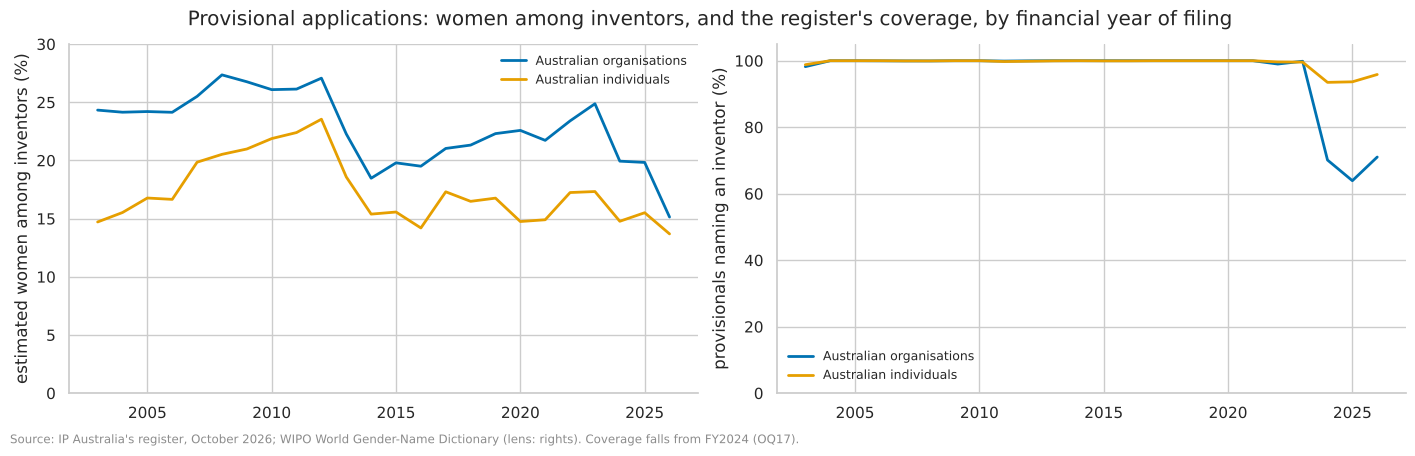

In [20]:
prov = rsql(
    """
    SELECT application_number, filing_fy,
           CASE WHEN filing_fy BETWEEN 2013 AND 2022 THEN 'FY2013-FY2022' WHEN filing_fy BETWEEN 2003 AND 2012
                THEN 'FY2003-FY2012' END AS period,
           @FILER AS filer, CASE WHEN founding_australian THEN founder_state END AS state,
           register_inventors AS named, register_inventors_women_expected AS women,
           register_inventors - register_inventors_gender_unknown AS estimated
    FROM {lens/rights}
    WHERE patent_type = 'provisional' AND filing_fy BETWEEN 2003 AND 2026 AND founding_australian IS NOT NULL
      AND founder_type IS NOT NULL
""",
    max_rows=None,
)
yearly = (
    prov.groupby(["filing_fy", "filer"])
    .apply(
        lambda d: pd.Series(
            {
                "with inventors (%)": 100 * (d.named > 0).mean(),
                "women (%)": 100 * d.women.sum() / max(d.estimated.sum(), 1),
            }
        ),
        include_groups=False,
    )
    .unstack("filer")
)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for f in ("Australian organisations", "Australian individuals"):
    axes[0].plot(yearly.index, yearly[("women (%)", f)], lw=2, label=f)
    axes[1].plot(yearly.index, yearly[("with inventors (%)", f)], lw=2, label=f)
axes[0].set_ylabel("estimated women among inventors (%)")
axes[0].set_ylim(0, 30)
axes[1].set_ylabel("provisionals naming an inventor (%)")
axes[1].set_ylim(0, 105)
for ax in axes:
    ax.legend(frameon=False, fontsize=9)
fig.suptitle(
    "Provisional applications: women among inventors, and the register's coverage, by financial year of filing"
)
style.source(
    fig,
    "IP Australia's register, October 2026; WIPO World Gender-Name Dictionary (lens: rights). "
    "Coverage falls from FY2024 (OQ17).",
)
pv = prov.dropna(subset=["period"])
by_pf = bi.ratio_by(pv, ["filer", "period"], "women", "estimated")
display((100 * by_pf[["ratio", "low", "high"]]).round(2).join(by_pf[["rows", "total"]]).unstack("period"))
by_st = bi.ratio_by(pv[pv.state.notna()], ["state", "period"], "women", "estimated")
display((100 * by_st[["ratio", "low", "high"]]).round(2).join(by_st["total"]).unstack("period"))
st = by_st[by_st.total >= 500].ratio.unstack("period").dropna()
print(
    "States with 500+ estimated inventors in both periods:",
    len(st),
    "; agreement of their order (Spearman rho):",
    round(st.corr(method="spearman").iloc[0, 1], 3),
)
yearly.loc[[2003, 2008, 2012, 2013, 2014, 2018, 2022, 2023, 2024, 2025, 2026]].round(2)

#### Observations
**B17 (observational). Women among inventors in Australia: the field matters more than the filer, and the order of
fields holds.** Standard patents, inventors in Australia (44,251 inventor places on 22,335 patents, 93.38% with an
estimate):
- **By field,** FY2010 to FY2019 (FY2000 to FY2009): from 4.2% in civil engineering (4.3%) and 5.2% in transport
  (4.1%) to 24.4% in pharmaceuticals (20.4%) and 26.9% in biotechnology (27.2%). The order of the 12 fields with
  enough inventors agrees between the decades with a Spearman rho of 0.86.
- **By filer:** Australian organisations 12.17% (11.78% to 12.62%) and 15.85% (14.99% to 16.74%); Australian
  individuals 11.21% (9.9% to 12.63%) and 11.55% (9.69% to 13.47%); overseas organisations 10.57% and 9.83%.
  Organisations' and individuals' intervals overlap in FY2010 to FY2019, so the filer gap does not replicate for
  standard patents.
- Expected counts from names, read for inventors in Australia only (U97). Third factor: the field (organisations
  file more in biotechnology and pharmaceuticals, individuals in transport and civil engineering, B4).

**B18 (observational). Provisional applications: organisations' inventors include more women than individuals', in
both decades, and the states' order holds.**
- **By filer,** FY2013 to FY2022 (FY2003 to FY2012): Australian organisations 21.19% (20.88% to 21.5%) and 25.52%;
  Australian individuals 16.14% (15.7% to 16.51%) and 18.89% (18.54% to 19.2%). Overseas
  organisations 6.66% and 6.05%.
- **By state:** the ACT highest in the later decade (25.59%; 27.03% before), Western Australia and New South Wales
  lowest (17.83% and 17.92%; 18.49% and 19.56%); South Australia fell from 32.23% to 21.92%. The seven states with 500
  or more estimated inventors keep their order with a Spearman rho of 0.821.
- **Coverage:** in the years shown from FY2003 to FY2023, 98.21% to 100% of provisionals name an inventor in every
  filer group, but
  Australian organisations' only 70.13% (FY2024), 63.91% (FY2025) and 71.03% (FY2026), against 93.49% to 95.86% for
  Australian individuals. The recent years' figures (Australian organisations 19.94%, 19.83%, 15.13%) cover two
  thirds of their provisionals, so they are not compared with earlier years until OQ17 is answered.
- The provisionals' estimates use the applicant's country, not the inventor's, and were checked against WIPO only for
  patents (U107), so they are levels within this source, not to be set beside B17's.

### 1.7 Rights moving overseas, by technology, applicant type and reach

**From:** U18. **Informs:** Q1, Q2. Standard patents filed from Australia whose holders today are all overseas,
filed FY2003 to FY2011 against FY2012 to FY2021 (IP RAPID records holders' changes from FY2003, U35). The older
period has had longer for its patents to change hands, so the two periods' levels differ by design; what should
hold is the pattern across groups. The firm's own age is a `firms` question (section 2).

share                         low                        high                       moved                           n              
period       FY2003-FY2011 FY2012-FY2021 FY2003-FY2011 FY2012-FY2021 FY2003-FY2011 FY2012-FY2021 FY2003-FY2011 FY2012-FY2021 FY2003-FY2011 FY2012-FY2021
founder_type                                                                                                                                            
individual            1.63          1.95          1.37          1.63          1.95          2.34           118           116          7218          5935
organisation          6.88           2.8           6.5          2.58          7.28          3.03          1101           556         15998         19884

share                         low                        high                       moved                           n              
period            FY2003-FY2011 FY2012-FY2021 FY2003-FY2011 FY2012-FY2021 FY2003-FY2011 FY2012-FY2021 FY2003-FY2011 FY2012-FY2021 FY2003-FY2011 FY2012-FY2021
reach                                                                                                                                                        
1 office                   3.75          1.16          3.45          0.97          4.08          1.37           539           127         14362         10984
2 to 4 offices              5.5          2.56          4.86          2.25          6.22          2.91           238           224          4328          8765
5 or more offices         14.52          6.25         13.28          5.62         15.85          6.95           421           319          2900          5104

share                         low                        high                       moved                           n              
period  FY2003-FY2011 FY2012-FY2021 FY2003-FY2011 FY2012-FY2021 FY2003-FY2011 FY2012-FY2021 FY2003-FY2011 FY2012-FY2021 FY2003-FY2011 FY2012-FY2021
granted                                                                                                                                            
False            1.15          0.87          0.97          0.73          1.35          1.04           142           126         12401         14463
True             9.96          4.81          9.41          4.43         10.54          5.22          1077           546         10815         11356

Fields in both periods: 27 ; agreement of their order (Spearman rho): 0.805
Highest and lowest fields, FY2012-FY2021:


period,FY2003-FY2011,FY2012-FY2021
main_area,,
20_materials_metallurgy,9.51,9.33
14_organic_fine_chemistry,6.51,8.21
15_biotechnology,5.07,7.96
4_digital_communication,5.45,6.43
33_furniture_games,1.3,1.05
30_thermal_processes_and_apparatus,3.71,1.02
25_handling,2.38,0.83


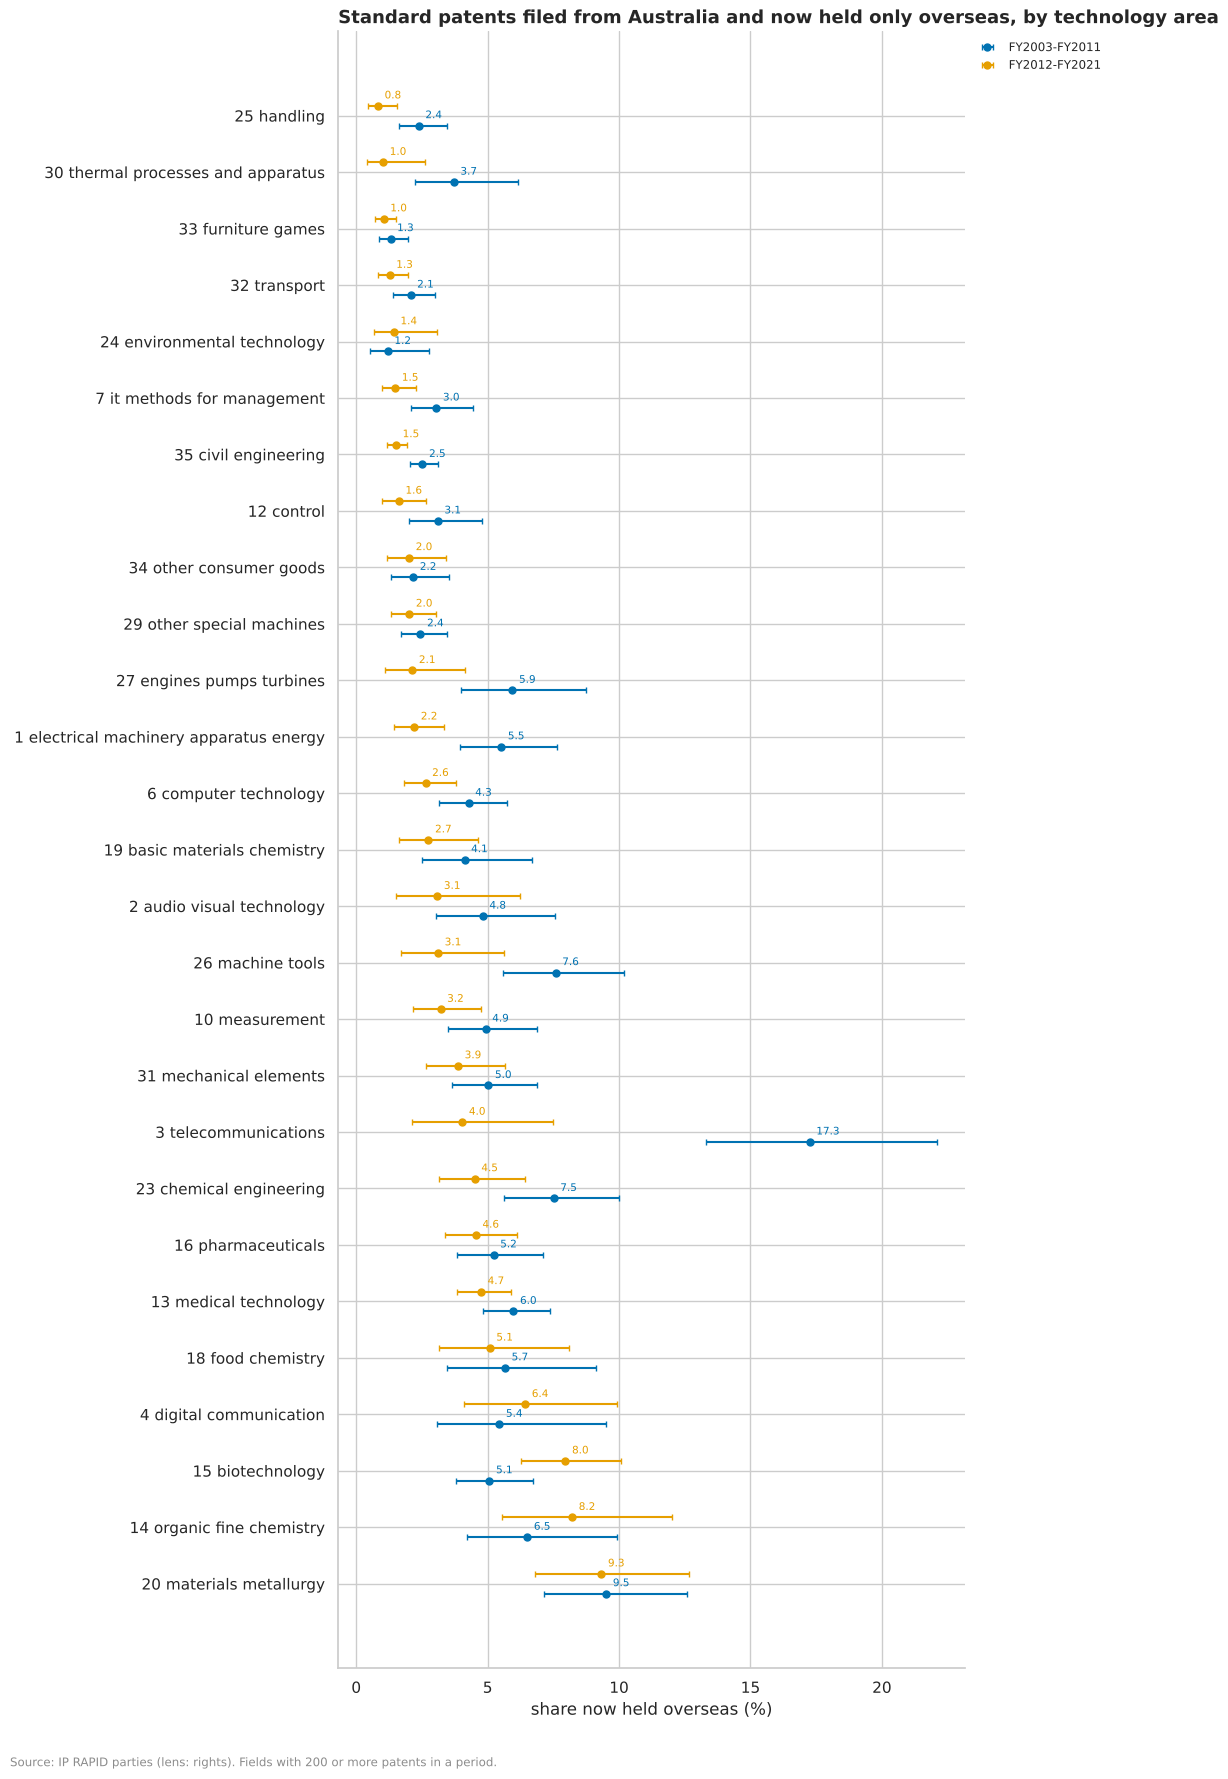

In [21]:
moved = rsql("""
    SELECT CASE WHEN filing_fy <= 2011 THEN 'FY2003-FY2011' ELSE 'FY2012-FY2021' END AS period, founder_type,
           main_area, CASE WHEN family_offices = 1 THEN '1 office' WHEN family_offices < 5 THEN '2 to 4 offices'
                           WHEN family_offices >= 5 THEN '5 or more offices' END AS reach,
           registered_date IS NOT NULL AS granted, count(*) AS n, count(*) FILTER (NOT australian_applicant) AS moved
    FROM {lens/rights}
    WHERE patent_type = 'standard' AND filing_fy BETWEEN 2003 AND 2021 AND founding_australian
      AND australian_applicant IS NOT NULL AND founder_type IS NOT NULL
    GROUP BY ALL
""")


def moved_by(col):
    t = moved.dropna(subset=[col]).groupby([col, "period"])[["moved", "n"]].sum()
    t["share"] = t.moved / t.n
    t["low"], t["high"] = bi.wilson(t.moved, t.n)
    return t


for col in ("founder_type", "reach", "granted"):
    t = moved_by(col)
    display((100 * t[["share", "low", "high"]]).round(2).join(t[["moved", "n"]]).unstack("period"))
area = moved_by("main_area")
area = area[area.n >= 200]
wide = area.share.unstack("period").dropna()
order = wide.sort_values("FY2012-FY2021").index
plot = area.reset_index().set_index("main_area").loc[order]
plot.index = plot.index.str.replace("_", " ")
fig = bi.dot_chart(
    plot,
    value="share",
    low="low",
    high="high",
    hue="period",
    title="Standard patents filed from Australia and now held only overseas, by technology area",
    xlabel="share now held overseas",
)
style.source(fig, "IP RAPID parties (lens: rights). Fields with 200 or more patents in a period.")
print(
    "Fields in both periods:",
    len(wide),
    "; agreement of their order (Spearman rho):",
    round(wide.corr(method="spearman").iloc[0, 1], 3),
)
ranked = (100 * wide).round(2).sort_values("FY2012-FY2021", ascending=False)
print("Highest and lowest fields, FY2012-FY2021:")
display(pd.concat([ranked.head(4), ranked.tail(3)]))

#### Observations
**B19 (observational). Patents that move overseas are the wider and the granted ones; organisations' move more, and
the order of fields holds.** Standard patents filed from Australia now held only overseas, FY2003 to FY2011 (FY2012 to
FY2021, which have had less time to change hands):
- **By reach:** five or more offices 14.52% (6.25%), two to four 5.5% (2.56%), one office 3.75% (1.16%).
- **Granted or not:** granted 9.96% (4.81%), never granted 1.15% (0.87%).
- **By filer:** organisations 6.88% (2.8%), individuals 1.63% (1.95%); the organisations' gap holds, smaller, in the
  later period.
- **By field:** highest in materials and metallurgy (9.33% in the later period; 9.51% earlier), organic fine chemistry
  (8.21%; 6.51%) and biotechnology (7.96%; 5.07%); lowest in handling (0.83%; 2.38%), thermal processes (1.02%; 3.71%)
  and furniture and games (1.05%; 1.3%). The 27 fields' order agrees with a Spearman rho of 0.805.
- **So** the rights that leave are the ones their owners valued most (wide and granted): a lead for Q1, since value
  created in Australia may be captured abroad. Third factors: reach and grant are tied to each other and to the field;
  the filing firm's age is in section 2.5.

### 1.8 Summary of the IP rights lens

| # | Pair | What was found | Strength | Holds in the second period? | Carried to Stage 3 |
|---|---|---|---|---|---|
| B1 | Every pair, six types | 223 distinct leads; the decades agree (rho 0.859) | descriptive | method | The leads below |
| B2 | Mechanics (PCT office, inventors, timing) | Expected from how rights are filed and recorded | descriptive | yes | No |
| B3 | Design status × origin | IP RAPID drops failed designs' origin; the register fills it | descriptive | yes | Rule: design origin from the filled column |
| B5 | Filer × filing alone | Australian individuals file alone most | observational | yes (not designs) | Yes, with B6 |
| B6 | Filing alone × grant | Standard patents 36 points less often granted (individuals); trade marks 23 to 24 | observational | yes (not organisations' patents) | Yes: Q4 (help to file) |
| B7 | Origin × time to grant | A 2010s gap only | observational | no | No; route as third factor |
| B8 | Origin × years in force | Australian organisations keep patents longer, within fields too | observational | yes | Yes: Q1, with selection at grant |
| B9 | Field × years in force | 59.4% to 81.2% in force at 10 years | descriptive | weakly (rho 0.459) | Only with B8 |
| B10 | Filer and representation × renewal | Trade marks and designs renewed least by Australian individuals and lone filers | observational | yes | Yes: Q2, Q4 |
| B11 | Origin × reach | Australian organisations narrower, gap narrowing | observational | yes | Yes: Q1 |
| B12 | Origin × citations | Mostly reach | observational | yes | Reach as third factor |
| B13 | Expedited × years in force | Holds for overseas organisations only; Simpson's paradox when pooled | observational | no (pooled) | Yes, by filer: Q1, Q4 |
| B14 | Expedited trade marks × renewal | 1 to 4 points | descriptive | partly | No |
| B15 | Filer × route | Distinct routes; divisionals doubled | descriptive | yes | Divisionals: lead |
| B16 | Invented here × filed from overseas | One in seven made here filed from abroad | descriptive | yes | Yes: Q1 |
| B17 | Field and filer × women among inventors | Field matters (4.2% to 26.9%), filer does not replicate | observational | yes (field) | Yes: Q2 gender analysis |
| B18 | Filer and state × women (provisionals) | Organisations about 5 points higher; states' order holds | observational | yes | Yes: Q2, after OQ17 |
| B19 | Reach, grant, field × moving overseas | Wider, granted, organisations' patents move most | observational | yes | Yes: Q1 |

**Candidate third factors named most often:** the filer (origin and type), family reach, the route of filing, the
technology field, and selection at grant. Stage 3 tests them together.

## 2. Lens: Firms (one row per ABN)

**Rules carried from Stage 1:** firms' IP counts are lower bounds (50,790 ABNs only IPLORD links to IP have counts of
0, U41); counts are compared by medians, ranks or logs, never means alone (U44); age is read with `age_truncated` (a
business first seen through its ABN or GST date before 2001 may be older, U43); an address is where a business is
registered, not where it works (U47). Firms are credited by the filer's ABN, filled from IP Australia's register
(ADR 0029).

**Who is in the lens matters here.** A business is in the lens because it appears in an IP, R&D, procurement or tax
source, so "the share of firms with IP" over the whole lens mostly measures how the lens was built. The planned pairs
therefore look within groups that came in through another door: R&D Tax Incentive claimants, government suppliers and
the large taxpayers in the ATO's transparency reports.

**The two samples.** Firms have no time dimension, so the discovery and replication samples are the two halves of the
lens by a hash of the ABN (about 230,000 each; the screen takes 200,000 of each).

### 2.0 The screen: every pair

verdict,lead,not replicated,negligible,not significant,by construction,too few rows,distinct leads
pairs,221,10,410,0,171,8,33


Agreement between the halves' strengths (Spearman): 0.962


,pair,measure,strength,95% interval,replication,size,versions,direction,candidate third factors
0,Average R&D spend claimed × Total income (latest year reported),spearman,0.485,0.406 to 0.552,0.346,moderate,8,rises with,"R&D spend claimed (latest year), Years in the tax transparency reports, Years claiming..."
1,Entity type (ABR) × Business may be older than its first public registration,cramer_v,0.441,0.434 to 0.450,0.438,moderate,7,Local Government Entity with True (15.9× chance),"Entity group, Register that set first_seen, Years since earliest public registration"
2,Entity type (ABR) × Rights held now,rank_eta,0.365,0.362 to 0.368,0.366,moderate,21,"Rights held now: highest median for State Government Statutory Authority (1), lowest f...","Entity group, Applicant or owner of a trade mark (IP RAPID), IP applications as a foun..."
3,ABN is active × Financial year of first trade mark application (filled),rank_eta,0.363,0.358 to 0.367,0.36,moderate,6,"Financial year of first trade mark application (filled): highest median for True (2,01...","Register that set first_seen, Financial year of first trade mark application, Financia..."
4,Entity type (ABR) × Applicant or owner of a trade mark (IP RAPID),cramer_v,0.353,0.350 to 0.357,0.35,moderate,13,ATO Regulated Self-Managed Superannuation Fund with False (2.0× chance),"Rights held now, Entity group, IP applications as a founding applicant (shared ones sp..."
5,Years since earliest public registration × Linked to IP by IPLORD (to FY2020),rank_eta,0.316,0.313 to 0.321,0.315,moderate,4,"Years since earliest public registration: highest median for True (16.1), lowest for F...","Financial year of first trade mark application (filled), Financial year of first trade..."
6,Has a government contract (AusTender) × Trade mark applications,rank_eta,0.316,0.312 to 0.320,0.314,moderate,11,"Trade mark applications: highest median for False (1), lowest for True (0)","An owner in IP Australia's register, Government contracts, Applicant or owner of a tra..."
7,ABN is active × Financial year of first design application (filled),rank_eta,0.311,0.290 to 0.330,0.307,moderate,4,"Financial year of first design application (filled): highest median for True (2,016), ...","Financial year of first trade mark application (filled), Register that set first_seen,..."
8,ABN is active × Financial year of first standard patent application (filled),rank_eta,0.282,0.260 to 0.297,0.26,small,8,Financial year of first standard patent application (filled): highest median for True ...,"Financial year of first trade mark application (filled), Financial year of first trade..."
9,Has a government contract (AusTender) × IP applications as a founding applicant,rank_eta,0.27,0.265 to 0.274,0.268,small,15,"IP applications as a founding applicant: highest median for False (1), lowest for True...","Trade mark applications, Applicant or owner of a trade mark (IP RAPID), IP application..."


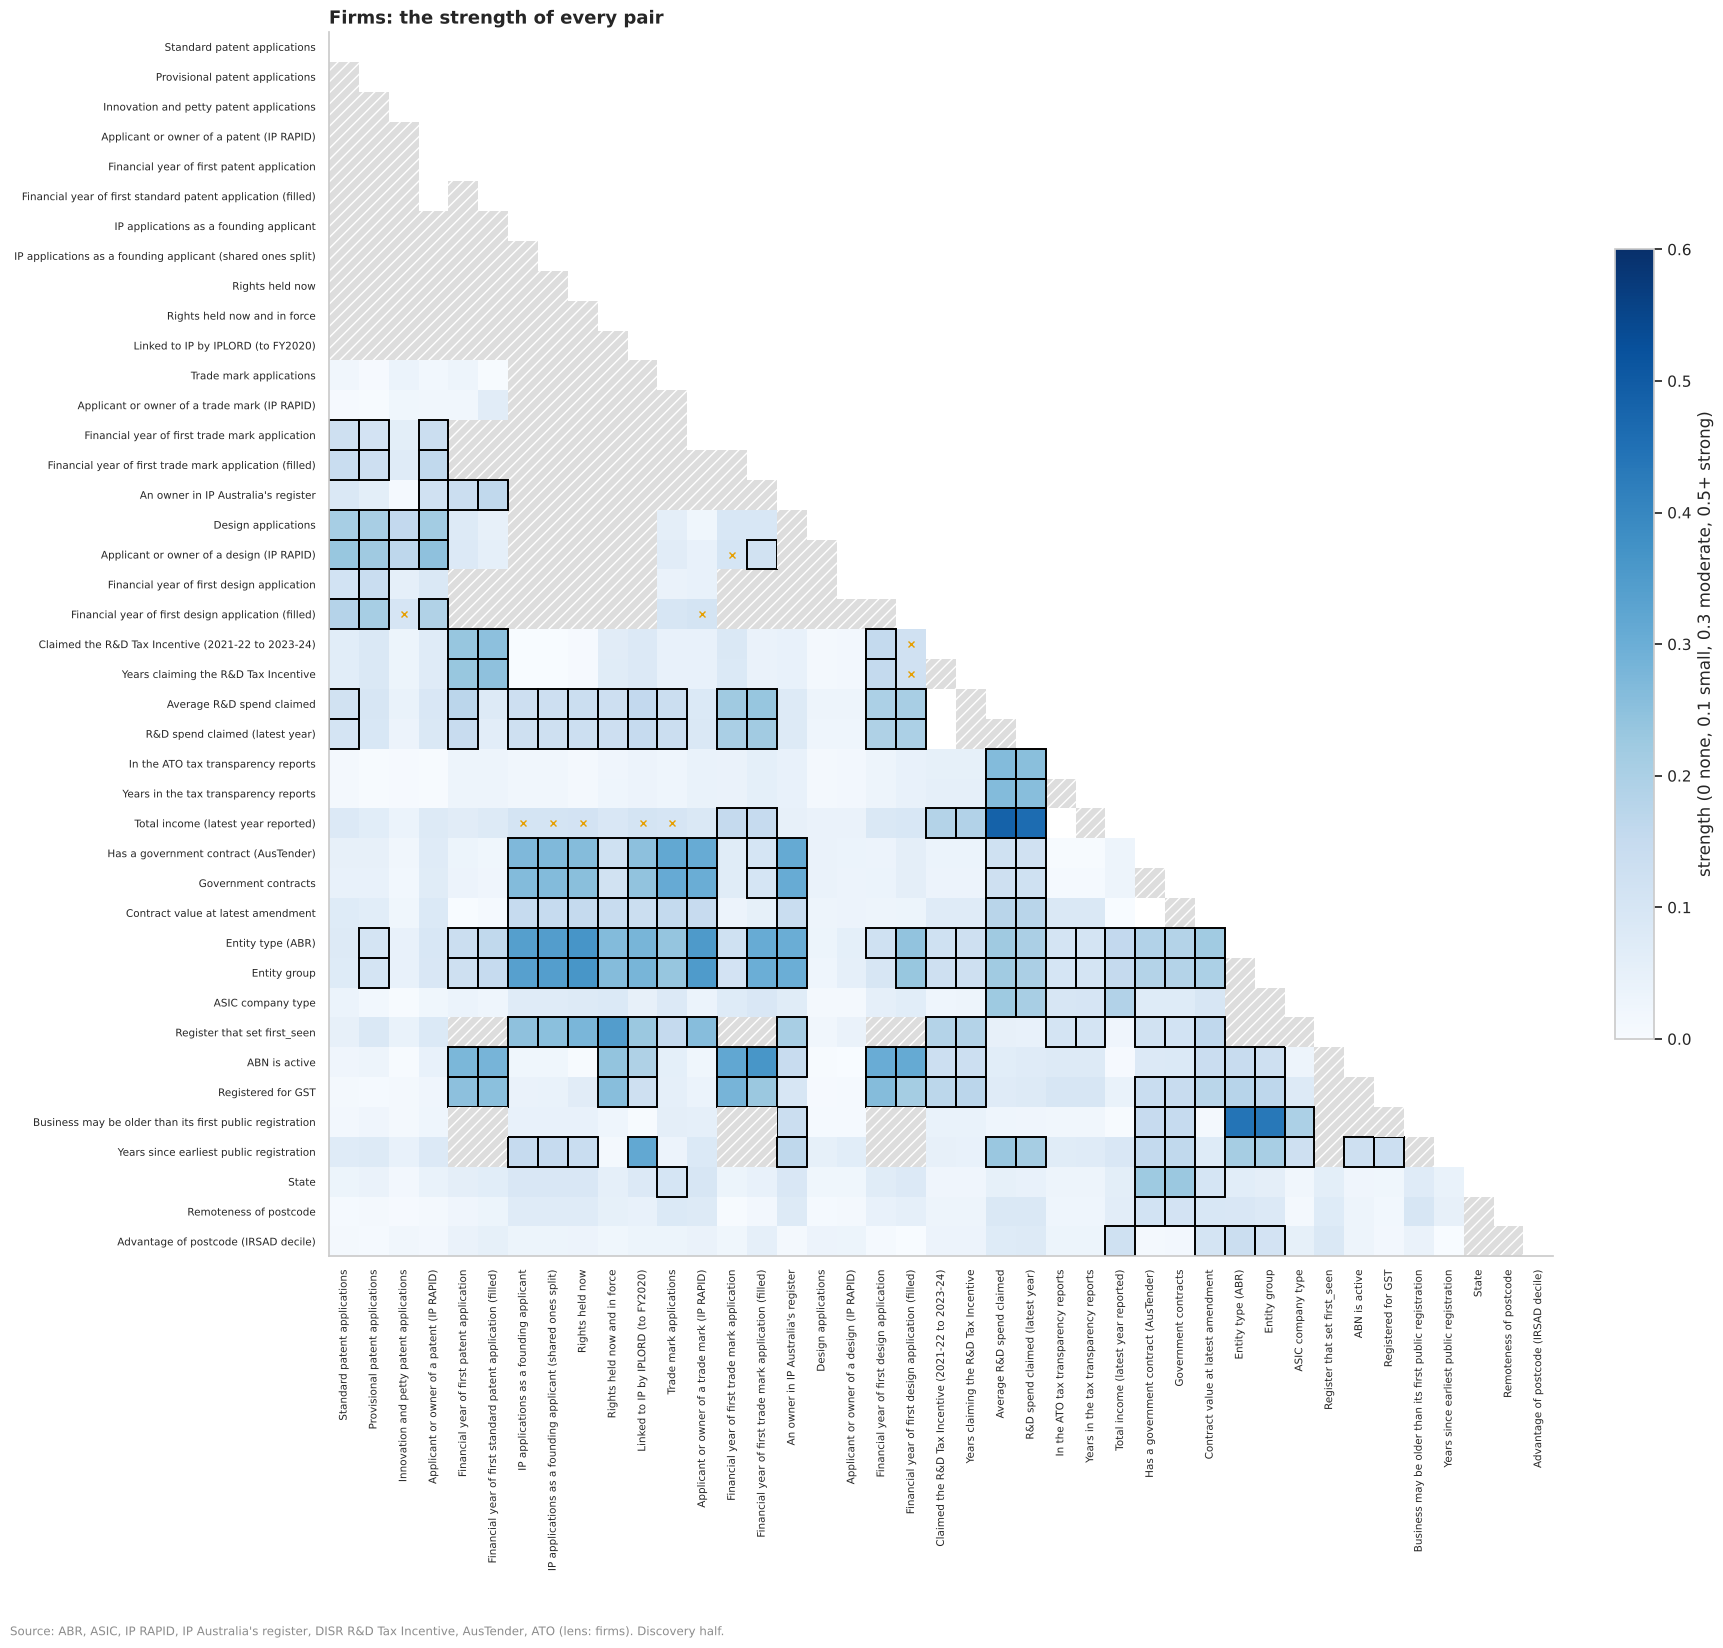

In [22]:
FIRM_GROUPS = bi.screens()["firms"]["groups"]


def flab(c):
    return bi.screen_label("firms", c)


firms_screen = bi.run_screen("firms")
firms_leads = bi.distinct_leads(firms_screen["verdicts"], FIRM_GROUPS)
display(bi.verdict_counts(firms_screen["verdicts"]).to_frame("pairs").T.assign(**{"distinct leads": len(firms_leads)}))
m = firms_screen["verdicts"]
measured = m.dropna(subset=["strength"])
cols = set(measured["variable 1"]) | set(measured["variable 2"])
order = list(dict.fromkeys([c for g in FIRM_GROUPS.values() for c in g if c in cols] + sorted(cols)))
fig = bi.strength_map(m, order, label=flab, title="Firms: the strength of every pair")
style.source(
    fig,
    "ABR, ASIC, IP RAPID, IP Australia's register, DISR R&D Tax Incentive, AusTender, ATO "
    "(lens: firms). Discovery half.",
)
ok = m.dropna(subset=["strength", "strength (replication)"])
print(
    "Agreement between the halves' strengths (Spearman):",
    round(
        ok[~ok["by construction"]].strength.corr(
            ok[~ok["by construction"]]["strength (replication)"], method="spearman"
        ),
        3,
    ),
)
firm_lead_table = bi.leads_table(firms_leads, firms_screen["prepared"], firms_screen["discovery"], label=flab)
with pd.option_context("display.max_rows", 100, "display.width", 250):
    display(firm_lead_table.round(3))

#### Observations
**B20 (descriptive). The screen of the firms lens: 33 distinct leads; the two halves agree almost exactly.** 221 pairs
are leads (33 distinct pairs of measures), 10 passed in one half only, 410 are negligible and 171 are related by
construction. The halves' strengths agree with a Spearman rho of 0.962: random halves of one population are a weaker
test than the rights lens's second decade, so the firms' leads rest more on their size and on the planned pairs below.

**B21 (observational). Most firm leads describe who is in the lens, or the registers' mechanics; a few are
substantive.**
- **How the lens was built:** a government supplier has fewer trade marks (a median 0 against 1; 0.316 in both halves),
  because a firm without a contract is in the lens only if it has IP or another link; entity type goes with rights
  held (0.365; 0.366) and with whether an older business's age is truncated (0.441; 0.438: local government 15.9 times
  chance), which is how ABNs began in 1999 and 2000.
- **Substantive, and followed up below:** larger firms both claim more R&D and report more income (average R&D spend ×
  total income, rho 0.485, interval 0.406 to 0.552, among the few firms that are both large taxpayers and claimants; 0.346
  in the other half); public
  companies claim far more R&D than proprietary ones (a median $1.381m against $0.297m; 0.225; 0.232); firms that hold
  patents also hold designs (5.5 times chance; 0.247; 0.248); R&D spend rises with contract value (0.176; 0.184); and
  government suppliers cluster in the ACT (a median of 1 contract against 0 in NSW; 0.229 in both halves).

### 2.1 Who files IP, among firms that came in through another door

**From:** U41 to U46. **Informs:** Q2, Q3. Among R&D Tax Incentive claimants, government suppliers and the large
taxpayers, the share that has filed any IP (as a founding applicant, `ip_filed_total`, or as the filer by the filled
ABN), by entity group, age and place. Active ABNs; each figure in both halves.

In [23]:
FILED = (
    "(ip_filed_total > 0 OR n_patents_standard + n_patents_provisional + n_patents_second_tier + n_trade_marks"
    " + n_designs > 0)"
)
HALF = "CASE WHEN hash(abn || 'stage2') % 2 = 0 THEN 'discovery' ELSE 'replication' END"
AGE = (
    "CASE WHEN age_truncated THEN 'first seen before 2001 (may be older)' WHEN age_years < 3 THEN 'under 3 years'"
    " WHEN age_years < 10 THEN '3 to 10 years' WHEN age_years < 20 THEN '10 to 20 years' ELSE '20 years or more' END"
)


def by_door(group, door):
    t = (
        sql(f"""
        SELECT {group} AS grp, {HALF} AS half, count(*) AS n, count(*) FILTER ({FILED}) AS filed,
               count(*) FILTER (n_patents_standard > 0) AS patent, count(*) FILTER (n_trade_marks > 0) AS trade_mark
        FROM {{lens/firms}} WHERE abn_active AND {door} GROUP BY ALL
    """)
        .dropna(subset=["grp"])
        .set_index(["grp", "half"])
        .sort_index()
    )
    for c in ("filed", "patent", "trade_mark"):
        t[f"{c} (%)"] = 100 * t[c] / t.n
    lo, hi = bi.wilson(t.filed, t.n)
    t["filed low"], t["filed high"] = 100 * lo, 100 * hi
    return t


DOORS = {
    "R&D Tax Incentive claimants": "in_rdti",
    "Government suppliers": "in_austender",
    "Large taxpayers (ATO transparency)": "in_ato_ctt",
}
overall = pd.concat({name: by_door("'all'", door) for name, door in DOORS.items()})
display(overall.droplevel(1)[["n", "filed (%)", "filed low", "filed high", "patent (%)", "trade_mark (%)"]].round(2))
for g, name in (
    ("entity_group", "entity group"),
    (AGE, "age"),
    ("remoteness", "remoteness"),
    ("irsad_decile", "advantage of postcode (IRSAD decile)"),
):
    t = pd.concat({d: by_door(g, door) for d, door in DOORS.items() if d != "Large taxpayers (ATO transparency)"})
    t = t[t.n >= 50]
    print(f"Share that has filed IP, by {name} (groups of 50 or more):")
    display(t[["n", "filed (%)", "filed low", "filed high"]].round(1).unstack("half"))

n  filed (%)  filed low  filed high  patent (%)  trade_mark (%)
                                   half                                                                            
R&D Tax Incentive claimants        discovery     8909      51.41      50.37       52.45       12.26           45.26
                                   replication   8734      51.89      50.84       52.94       12.71            45.8
Government suppliers               discovery    26287      25.02       24.5       25.54        3.12           23.75
                                   replication  26597      25.09      24.57       25.61        3.21           23.95
Large taxpayers (ATO transparency) discovery     3184      40.45      38.76       42.17        7.54           39.35
                                   replication   3126       41.2      39.49       42.94        8.06           39.32

Share that has filed IP, by entity group (groups of 50 or more):


n             filed (%)             filed low             filed high            
half                                        discovery replication discovery replication discovery replication  discovery replication
                            grp                                                                                                     
R&D Tax Incentive claimants Private company      8429        8210      50.7        51.1      49.7          50       51.8        52.2
                            Public company        459         510      63.8        64.7      59.3        60.5       68.1        68.7
Government suppliers        Government            673         651      39.4        46.1      35.8        42.3       43.1        49.9
                            Other                1487        1482      29.5        28.1      27.2        25.9       31.8        30.5
                            Partnership           703         721       6.5         6.1       4.9         4.6        8.6         8.1
                            Private company     15064       15307      31.4        31.2      30.7        30.5       32.2          32
                            Public company       1236        1273      65.1        63.7      62.4          61       67.7        66.3
                            Sole trader          3650        3711       1.2         1.3       0.9           1        1.6         1.7
                            Super fund             63          73         0         2.7        -0         0.8        5.7         9.5
                            Trust                3411        3379       7.2           8       6.4         7.1        8.2           9

Share that has filed IP, by age (groups of 50 or more):


n             filed (%)             filed low             filed high            
half                                                              discovery replication discovery replication discovery replication  discovery replication
                            grp                                                                                                                           
R&D Tax Incentive claimants 10 to 20 years                             2633        2593      55.7        56.8      53.8        54.9       57.6        58.7
                            20 years or more                           1782        1766      67.4        66.6      65.2        64.4       69.5        68.8
                            3 to 10 years                              4350        4208        43        43.4      41.6          42       44.5        44.9
                            under 3 years                               134         152      26.9        30.3      20.1        23.5       34.9          38
Government suppliers        10 to 20 years                             7251        7398      20.6        20.9      19.7          20       21.6        21.8
                            20 years or more                          10436       10657      35.7        35.6      34.8        34.7       36.7        36.5
                            3 to 10 years                              4168        4131      14.2        13.9      13.2        12.9       15.3          15
                            first seen before 2001 (may be older)      3781        3752      19.5        19.8      18.3        18.6       20.8        21.1
                            under 3 years                               651         659       3.2         2.9       2.1         1.9        4.9         4.5

Share that has filed IP, by remoteness (groups of 50 or more):


n             filed (%)             filed low             filed high            
half                                                  discovery replication discovery replication discovery replication  discovery replication
                            grp                                                                                                               
R&D Tax Incentive claimants Inner Regional Australia        630         646      49.8        51.4      45.9        47.5       53.7        55.2
                            Major Cities of Australia      8007        7824      51.9        52.1      50.8          51         53        53.2
                            Outer Regional Australia        234         229      39.3        46.7      33.3        40.4       45.7        53.2
Government suppliers        Inner Regional Australia       3017        2939      17.1        16.4      15.8        15.1       18.5        17.8
                            Major Cities of Australia     20489       20877      27.8          28      27.2        27.4       28.4        28.6
                            Outer Regional Australia       1930        1912        13          12      11.6        10.6       14.6        13.5
                            Remote Australia                354         353      10.5        10.8       7.7         7.9       14.1        14.4
                            Very Remote Australia           357         375       8.4         8.3       5.9         5.9       11.7        11.5

Share that has filed IP, by advantage of postcode (IRSAD decile) (groups of 50 or more):


n             filed (%)             filed low             filed high            
half                            discovery replication discovery replication discovery replication  discovery replication
                            grp                                                                                         
R&D Tax Incentive claimants 1         163         186      48.5        55.4      40.9        48.2       56.1        62.3
                            2         309         326        57        51.2      51.4        45.8       62.4        56.6
                            3         231         221      48.9        47.5      42.5          41       55.3        54.1
                            4         372         335      49.7        52.8      44.7        47.5       54.8        58.1
                            5         351         379      51.9        46.4      46.6        41.5         57        51.5
                            6         506         469        54        51.4      49.6        46.9       58.2        55.9
                            7         515         521      54.2        55.5      49.9        51.2       58.4        59.7
                            8        1063        1075      50.8        50.3      47.8        47.3       53.8        53.3
                            9        1865        1789      50.9        51.1      48.6        48.8       53.1        53.5
                            10       3468        3377      50.9        52.7      49.3        51.1       52.6        54.4
Government suppliers        1         985         974      20.2        21.4      17.8        18.9       22.8          24
                            2        1185        1226      23.1        22.1      20.8        19.9       25.6        24.5
                            3         921         880      19.8        21.7      17.3        19.1       22.5        24.5
                            4        1324        1333      19.4        19.8      17.4        17.8       21.6          22
                            5        1581        1569      20.3        19.6      18.4        17.7       22.4        21.6
                            6        1538        1513      22.5        22.4      20.5        20.4       24.7        24.6
                            7        1565        1584      24.3        22.2      22.3        20.2       26.5        24.3
                            8        2797        2878        25        23.8      23.4        22.2       26.6        25.4
                            9        5137        5228      26.7        26.8      25.5        25.6       27.9          28
                            10       8986        9146      27.1        27.9      26.2          27       28.1        28.8

In [24]:
# The gradient by advantage of postcode, as one number per door and half: Spearman's rho between IRSAD decile and
# the share that has filed IP (10 deciles)
rows = []
for d, door in DOORS.items():
    if d.startswith("Large"):
        continue
    t = by_door("irsad_decile", door).reset_index()
    for h, g in t.groupby("half"):
        rho = g.grp.astype(float).corr(g["filed (%)"], method="spearman")
        lo, hi = g["filed (%)"].iloc[0], g["filed (%)"].iloc[-1]
        rows.append({"door": d, "half": h, "rho (decile, share)": rho, "decile 1 (%)": lo, "decile 10 (%)": hi})
pd.DataFrame(rows).set_index(["door", "half"]).round(3)

rho (decile, share)  decile 1 (%)  decile 10 (%)
door                        half                                                         
R&D Tax Incentive claimants discovery                  0.236         48.47          50.92
                            replication               -0.055         55.38          52.74
Government suppliers        discovery                  0.806          20.2          27.14
                            replication                0.782         21.36          27.88

#### Observations
**B22 (observational). Among firms that came in through another door, filing IP goes with being a company, older, and
in a city; and, for government suppliers, with an advantaged postcode.** Active ABNs, discovery half (replication):
- **Overall:** 51.41% of R&D Tax Incentive claimants have filed IP (51.89%), 25.02% of government suppliers (25.09%),
  and 40.45% of the large taxpayers (41.2%). Trade marks dominate: 45.26%, 23.75% and 39.35% have filed one; standard
  patents 12.26%, 3.12% and 7.54%.
- **Entity group (government suppliers):** public companies 65.1% (63.7%), private companies 31.4% (31.2%), trusts
  7.2% (8.0%), partnerships 6.5% (6.1%), sole traders 1.2% (1.3%). Claimants: public companies 63.8% (64.7%), private
  50.7% (51.1%).
- **Age:** claimants under 3 years old 26.9% (30.3%), 20 years or more 67.4% (66.6%); suppliers 3.2% (2.9%) and
  35.7% (35.6%). Age is partly time: an older firm has had longer to file.
- **Remoteness (suppliers):** major cities 27.8% (28.0%), inner regional 17.1% (16.4%), very remote 8.4% (8.3%).
- **Advantage of postcode:** for suppliers the share rises steadily from 20.2% in the most disadvantaged tenth of
  postcodes to 27.14% in the most advantaged (Spearman rho over the deciles 0.806; 0.782 in the other half). For R&D
  claimants there is no gradient (rho 0.236, then -0.055; 48.47% to 50.92%, then 55.38% to 52.74%): once a firm does
  R&D, where it is registered does not go with filing.
- **Third factors:** firm size (companies, older firms and city firms are larger), industry (not in the ABR), and
  where a business is registered rather than where it works (U47).

### 2.2 IP and R&D: spend, and the claimants who have never filed ('missing filers')

**From:** U41, U54. **Informs:** Q3, Q4. Among active R&D Tax Incentive claimants: does more R&D spend go with
patenting, and where are the claimants who have never filed IP? A missing filer is a claimant with no IP application
as a founding applicant (`ip_filed_total` = 0, as the `regions` lens counts them, U54); the count is an upper bound,
since IPLORD links some of them to IP that IP RAPID gives no ABN (shown beside). The ABR gives no industry, so
missing filers by industry wait for the `industries` lens.

Active claimants with a recorded R&D spend: 17,514


claimants             median_spend                patent             trade_mark             never_filed            
half         discovery replication    discovery replication discovery replication  discovery replication   discovery replication
spend_decile                                                                                                                    
1                  893         859    4.479e+04   4.493e+04       9.5         9.8       39.8        39.7          54          54
2                  911         841    8.779e+04   8.874e+04       9.8         9.2       40.4        41.7        54.2        54.9
3                  852         900    1.384e+05   1.384e+05       8.3        10.4       41.1        42.2        55.5        54.4
4                  879         873    2.005e+05       2e+05       8.1         7.1       42.3        42.8        55.2        53.4
5                  901         850    2.754e+05   2.783e+05      10.4        10.7       46.9        46.7        50.4        50.8
6                  878         873    3.829e+05   3.826e+05        13        11.2       46.5          47        48.3        50.3
7                  885         866    5.343e+05   5.352e+05      11.3        12.2         45        50.9        49.9        45.8
8                  897         854    8.152e+05   8.034e+05      10.9        15.6       47.9        49.1        49.6          48
9                  877         874    1.392e+06   1.396e+06        18        16.8       51.9        49.7        44.9        48.1
10                 868         883     3.79e+06   3.368e+06      24.1        24.3       51.8        49.8        45.5        44.4

discovery: rho(R&D spend, standard patents) = 0.120; rho(R&D spend, trade marks) = 0.135; n = 8,841
replication: rho(R&D spend, standard patents) = 0.128; rho(R&D spend, trade marks) = 0.124; n = 8,673


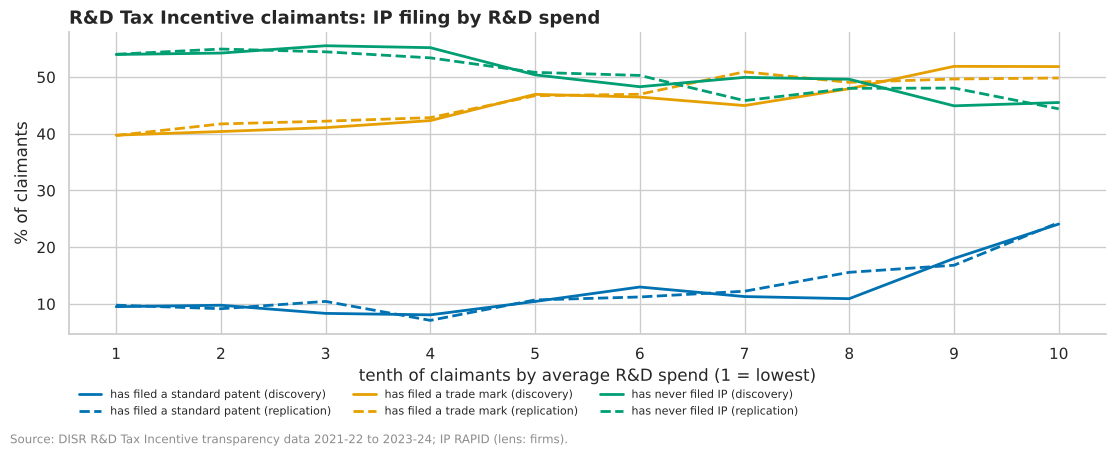

In [25]:
rd = sql(
    f"""
    SELECT {HALF} AS half, ntile(10) OVER (ORDER BY rd_expenditure_mean) AS spend_decile, rd_expenditure_mean,
           n_patents_standard, n_trade_marks, ip_filed_total, in_iplord, entity_group, state, remoteness,
           irsad_decile, {AGE} AS age
    FROM {{lens/firms}} WHERE abn_active AND in_rdti AND rd_expenditure_mean > 0
""",
    max_rows=None,
)
print(f"Active claimants with a recorded R&D spend: {len(rd):,}")
dec = rd.groupby(["spend_decile", "half"]).agg(
    claimants=("rd_expenditure_mean", "size"),
    median_spend=("rd_expenditure_mean", "median"),
    patent=("n_patents_standard", lambda s: (s > 0).mean()),
    trade_mark=("n_trade_marks", lambda s: (s > 0).mean()),
    never_filed=("ip_filed_total", lambda s: (s == 0).mean()),
)
display((dec.assign(**{c: 100 * dec[c] for c in ("patent", "trade_mark", "never_filed")})).round(1).unstack("half"))
for h, g in rd.groupby("half"):
    s1 = bi.pair_stats(np.log10(g.rd_expenditure_mean), g.n_patents_standard)
    s2 = bi.pair_stats(np.log10(g.rd_expenditure_mean), g.n_trade_marks)
    print(
        f"{h}: rho(R&D spend, standard patents) = {s1['spearman rho']:.3f};",
        f"rho(R&D spend, trade marks) = {s2['spearman rho']:.3f}; n = {s1['n']:,.0f}",
    )
plot = dec.reset_index()
fig, ax = plt.subplots(figsize=(11, 4.2))
for i, (col, name) in enumerate(
    (
        ("patent", "has filed a standard patent"),
        ("trade_mark", "has filed a trade mark"),
        ("never_filed", "has never filed IP"),
    )
):
    for h, ls in (("discovery", "-"), ("replication", "--")):
        d = plot[plot.half == h]
        ax.plot(d.spend_decile, 100 * d[col], ls=ls, color=style.PALETTE[i], lw=2, label=f"{name} ({h})")
ax.set_xticks(range(1, 11))
ax.set_xlabel("tenth of claimants by average R&D spend (1 = lowest)")
ax.set_ylabel("% of claimants")
ax.legend(frameon=False, fontsize=8, ncol=3, loc="upper left", bbox_to_anchor=(0, -0.15))
ax.set_title("R&D Tax Incentive claimants: IP filing by R&D spend")
style.source(fig, "DISR R&D Tax Incentive transparency data 2021-22 to 2023-24; IP RAPID (lens: firms).")

In [26]:
mf = []
for col, name in (
    ("state", "state"),
    ("remoteness", "remoteness"),
    ("irsad_decile", "IRSAD decile"),
    ("entity_group", "entity group"),
    ("age", "age"),
):
    t = (
        rd.dropna(subset=[col])
        .groupby([col, "half"])
        .agg(
            n=("ip_filed_total", "size"),
            missing=("ip_filed_total", lambda s: (s == 0).sum()),
            iplord=("in_iplord", lambda s: s.fillna(False).sum()),
        )
    )
    t = t[t.n >= 50]
    t["missing filers (%)"] = 100 * t.missing / t.n
    lo, hi = bi.wilson(t.missing, t.n)
    t["low"], t["high"] = 100 * lo, 100 * hi
    t["of whom IPLORD links to IP (%)"] = 100 * t.iplord / t.n
    mf.append(t.assign(by=name).reset_index().rename(columns={col: "group"}))
mf = pd.concat(mf).set_index(["by", "group", "half"])
mf[["n", "missing filers (%)", "low", "high", "of whom IPLORD links to IP (%)"]].round(1).unstack("half")

n             missing filers (%)                   low                  high              \
half                                    discovery replication          discovery replication discovery replication discovery replication   
by           group                                                                                                                         
IRSAD decile 1                                163         185               52.1        46.5      44.5        39.4      59.7        53.7   
             2                                305         324               45.6        50.6      40.1        45.2      51.2          56   
             3                                228         219               51.8        53.9      45.3        47.3      58.2        60.4   
             4                                366         333               53.3        49.2      48.2        43.9      58.3        54.6   
             5                                350         375               50.6        54.1      45.4        49.1      55.8        59.1   
             6                                500         466               48.2          50      43.9        45.5      52.6        54.5   
             7                                513         517               47.4        47.2      43.1        42.9      51.7        51.5   
             8                               1054        1070               51.2          52      48.2          49      54.2        54.9   
             9                               1855        1780               51.7        51.1      49.4        48.7        54        53.4   
             10                              3442        3349               51.2          50      49.5        48.3      52.9        51.7   
age           10 to 20 years                 2616        2584               46.8        45.7      44.8        43.8      48.7        47.6   
              20 years or more               1775        1761               35.8        36.7      33.6        34.5      38.1          39   
              3 to 10 years                  4307        4163               58.6        58.5      57.1          57      60.1          60   
              under 3 years                   133         150               74.4        71.3      66.4        63.6      81.1          78   
entity group  Private company                8361        8149               51.4        51.1      50.3          50      52.5        52.1   
              Public company                  459         510               39.9        39.8      35.5        35.6      44.4        44.1   
remoteness    Inner Regional Australia        623         644               52.3        50.8      48.4        46.9      56.2        54.6   
              Major Cities of Australia      7949        7767               50.3        50.2      49.2        49.1      51.4        51.3   
              Outer Regional Australia        232         227               62.1        56.8      55.7        50.3      68.1        63.1   
state         ACT                             121         126               35.5          50      27.6        41.4      44.4        58.6   
              NSW                            3214        3117               50.4        49.9      48.6        48.1      52.1        51.6   
              QLD                            1513        1559               51.8        52.3      49.3        49.8      54.3        54.7   
              SA                              477         481               49.9        47.8      45.4        43.4      54.4        52.3   
              TAS                              82          79               53.7        58.2      42.9        47.2        64        68.5   
              VIC                            2457        2393               50.6        50.1      48.6        48.1      52.6        52.1   
              WA                              952         895               52.4        50.3      49.2          47      55.6    

#### Observations
**B23 (observational). More R&D spend goes with patenting, but only weakly; about half of claimants have never filed
IP at any spend.** 17,514 active claimants with a recorded spend:
- **Standard patents:** 9.5% of the lowest-spending tenth of claimants (median $44,790 a year) have filed one, rising
  to 24.1% of the highest-spending tenth (median $3.79m); 9.8% and 24.3% in the other half. Spearman's rho between
  spend and patent applications is 0.120 (0.128): small.
- **Never filed IP:** 54% of the lowest-spending tenth and 45.5% of the highest (54% and 44.4%).
- **Missing filers (no IP as a founding applicant)** are most common among young claimants (under 3 years: 74.4%;
  71.3%) and least among the oldest (20 years or more: 35.8%; 36.7%), more common among private companies (51.4%;
  51.1%) than public ones (39.9%; 39.8%), and somewhat more common in outer regional areas (62.1%; 56.8%) than in
  major cities (50.3%; 50.2%). They do not vary with the advantage of the postcode (from 45.6% to 53.3% across the
  deciles, with no order).
- **An upper bound for older firms:** IPLORD links 54.3% (56.2%) of the oldest missing filers to IP that IP RAPID
  gives no ABN, against 10.4% (9.8%) of those 3 to 10 years old and none under 3. Among young claimants the count is
  close to exact.
- **So** the claimants who do R&D but have never filed IP are mostly young private companies, wherever they are: a lead
  for Q4 (where an intervention could add most), with industry, which the ABR does not give, as the main missing third
  factor.

### 2.3 IP and government contracts, and income

**From:** U46. **Informs:** Q3. Among active government suppliers: do firms that have filed IP win more or larger
contracts? Among the large taxpayers: do those with IP report higher income? Both halves; medians, with the
rank-biserial correlation as the size of the difference.

In [27]:
sup = sql(
    f"""
    SELECT {HALF} AS half, {FILED} AS filed, entity_group, austender_contracts, austender_value, total_income_latest,
           in_austender, in_ato_ctt
    FROM {{lens/firms}} WHERE abn_active AND (in_austender OR in_ato_ctt)
""",
    max_rows=None,
)
rows = []
for (h, who), d in (
    *(((h, "government suppliers"), g[g.in_austender.fillna(False)]) for h, g in sup.groupby("half")),
    *(((h, "large taxpayers"), g[g.in_ato_ctt.fillna(False)]) for h, g in sup.groupby("half")),
):
    for col in ["austender_contracts", "austender_value"] if who == "government suppliers" else ["total_income_latest"]:
        dd = d.dropna(subset=[col])
        a, b = dd[dd.filed][col], dd[~dd.filed][col]
        diff, lo, hi = bi.median_difference(a, b)
        rb = bi.compare_groups(pd.Series(np.r_[a, b]), pd.Series([0] * len(a) + [1] * len(b)))
        rows.append(
            {
                "who": who,
                "measure": col,
                "half": h,
                "with IP": len(a),
                "without": len(b),
                "median with IP": a.median(),
                "median without": b.median(),
                "difference": diff,
                "low": lo,
                "high": hi,
                "rank-biserial": rb["rank-biserial"],
            }
        )
pd.DataFrame(rows).set_index(["who", "measure", "half"]).round(3)

with IP  without  median with IP  median without  difference        low      high  rank-biserial
who                  measure             half                                                                                                         
government suppliers austender_contracts discovery       6576    19711               3               2           1          1         2          0.226
                     austender_value     discovery       6576    19711       2.734e+05       1.138e+05   1.597e+05  1.357e+05  1.85e+05          0.205
                     austender_contracts replication     6672    19925               3               2           1          1         2          0.229
                     austender_value     replication     6672    19925       2.773e+05         1.1e+05   1.673e+05  1.492e+05 1.951e+05          0.212
large taxpayers      total_income_latest discovery       1288     1896       2.146e+08       1.868e+08   2.782e+07  1.338e+07 4.504e+07          0.079
                                         replication     1288     1838        2.04e+08       2.002e+08   3.746e+06 -8.291e+06 1.949e+07           0.04

In [28]:
# Within entity groups (a candidate third factor: companies both file IP and win contracts more than sole traders)
rows = []
for (h, eg), d in sup[sup.in_austender.fillna(False)].groupby(["half", "entity_group"]):
    a, b = d[d.filed].austender_value.dropna(), d[~d.filed].austender_value.dropna()
    if len(a) >= 50 and len(b) >= 50:
        rb = bi.compare_groups(pd.Series(np.r_[a, b]), pd.Series([0] * len(a) + [1] * len(b)))
        rows.append(
            {
                "entity group": eg,
                "half": h,
                "with IP": len(a),
                "without": len(b),
                "median value with IP": a.median(),
                "median value without": b.median(),
                "rank-biserial": rb["rank-biserial"],
            }
        )
pd.DataFrame(rows).set_index(["entity group", "half"]).round(3).unstack("half")

with IP               without             median value with IP             median value without             rank-biserial            
half            discovery replication discovery replication            discovery replication            discovery replication     discovery replication
entity group                                                                                                                                           
Government            265         300       408         351            1.111e+06   1.123e+06            1.982e+05   1.795e+05         0.387       0.317
Other                 438         417      1049        1065            4.109e+05   4.251e+05            1.117e+05   1.081e+05          0.27       0.265
Private company      4732        4780     10332       10527            2.363e+05   2.385e+05            1.452e+05   1.335e+05         0.114       0.126
Public company        805         811       431         462            6.323e+05   5.737e+05            2.434e+05   2.051e+05           0.2       0.214
Trust                 247         270      3164        3109            1.207e+05   1.085e+05            9.243e+04   9.557e+04         0.044       0.065

#### Observations
**B24 (observational). Government suppliers that have filed IP win more and larger contracts, within every kind of
entity; large taxpayers with IP do not report clearly more income.**
- **Suppliers:** a median 3 contracts against 2 (both halves) and a median contract value of $273,400 against
  $113,800 (a difference of $159,700, interval $135,700 to $185,000; rank-biserial 0.205); replication $277,300 against
  $110,000 (0.212).
- **Within entity groups** the gap holds in both halves: private companies (rank-biserial 0.114; 0.126), public
  companies (0.2; 0.214), government bodies (0.387; 0.317), other entities (0.27; 0.265); for trusts it is negligible
  (0.044; 0.065).
- **Large taxpayers:** median income $214.6m with IP against $186.8m without (rank-biserial 0.079), and $204.0m against
  $200.2m in the other half (0.04; interval -$8.3m to $19.5m, which includes no difference): not a lead.
- **Not a cause:** IP and contracts may both follow from a firm's size and capability. Firm size (employees, turnover)
  is not in the lens; it is the main candidate third factor.

### 2.4 How old firms are when they first file

**From:** U43, U45. **Informs:** Q2. A firm's age at its first application of each kind, for first filings FY2010 to
FY2026 (filled from the register, so the years after FY2024 count), among firms whose first public registration is not
truncated (first seen in 2001 or later, so their age is real). Age is measured from the first public registration to
the middle of the financial year of first filing.

firms                median                   p25                   p75               under_1               over_10            
half            discovery replication discovery replication discovery replication discovery replication discovery replication discovery replication
kind                                                                                                                                               
design               2993        2941      4.72        4.23      1.24        0.96        12       11.23     22.65       25.57     30.27       28.15
standard patent      4025        4092      4.62        4.76         2           2     11.36       11.48     13.39       13.42     28.42       28.32
trade mark          73458       73501      2.03        2.06      0.07        0.08      6.85        6.97     39.61       39.26     16.71       17.05

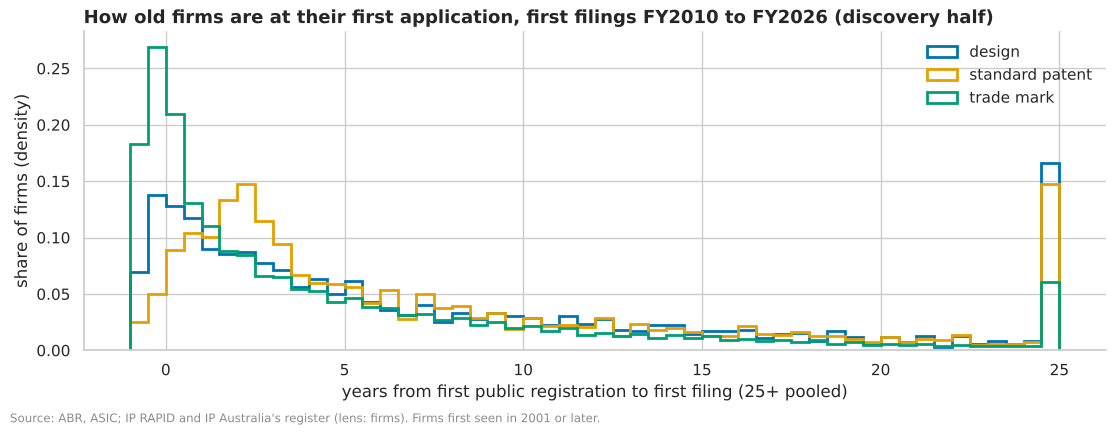

In [29]:
first = sql(
    f"""
    SELECT {HALF} AS half, kind, entity_group, (fy - 0.5) - (year(first_seen) + dayofyear(first_seen) / 365.25) AS age
    FROM (SELECT abn, first_seen, entity_group, age_truncated, 'standard patent' AS kind, patent_first_fy_filled AS fy
          FROM {{lens/firms}} UNION ALL
          SELECT abn, first_seen, entity_group, age_truncated, 'trade mark', trade_mark_first_fy_filled
          FROM {{lens/firms}} UNION ALL
          SELECT abn, first_seen, entity_group, age_truncated, 'design', design_first_fy_filled FROM {{lens/firms}})
    WHERE fy BETWEEN 2010 AND 2026 AND NOT age_truncated AND first_seen IS NOT NULL
""",
    max_rows=None,
)
first = first[first.age > -1]
t = first.groupby(["kind", "half"]).age.agg(
    firms="size",
    median="median",
    p25=lambda s: s.quantile(0.25),
    p75=lambda s: s.quantile(0.75),
    under_1=lambda s: 100 * (s < 1).mean(),
    over_10=lambda s: 100 * (s >= 10).mean(),
)
display(t.round(2).unstack("half"))
fig, ax = plt.subplots(figsize=(11, 4))
for i, (k, d) in enumerate(first[first.half == "discovery"].groupby("kind")):
    ax.hist(
        d.age.clip(upper=25),
        bins=np.arange(-1, 25.5, 0.5),
        density=True,
        histtype="step",
        lw=2,
        color=style.PALETTE[i],
        label=k,
    )
ax.set_xlabel("years from first public registration to first filing (25+ pooled)")
ax.set_ylabel("share of firms (density)")
ax.legend(frameon=False)
ax.set_title("How old firms are at their first application, first filings FY2010 to FY2026 (discovery half)")
style.source(fig, "ABR, ASIC; IP RAPID and IP Australia's register (lens: firms). Firms first seen in 2001 or later.")

#### Observations
**B25 (descriptive). Firms file their first trade mark early, their first patent or design later.** Firms first seen
in 2001 or later, first filings FY2010 to FY2026 (other half):
- **Trade marks:** a median 2.03 years after the firm's first public registration (2.06); 39.61% (39.26%) within the
  first year; 16.71% (17.05%) after 10 years or more.
- **Standard patents:** a median 4.62 years (4.76); 13.39% (13.42%) within the first year; 28.42% (28.32%) after 10
  years or more.
- **Designs:** a median 4.72 years (4.23).
- Age counts from the first public registration (ABN, GST or ASIC), a lower bound on the business's start (U43), so
  these are lower bounds on age at first filing.

### 2.5 Rights moving overseas, by the filing firm's age

**From:** U18 (section 1.7). **Informs:** Q1, Q2. Standard patents filed from Australia by a firm with an ABN, FY2003
to FY2021, joined to the firm: the share now held only overseas, by the firm's age when it filed (firms first seen in
2001 or later only, so ages run to about 20 years), in the two periods of section 1.7.

In [30]:
mv = (
    sql("""
    SELECT CASE WHEN r.filing_fy <= 2011 THEN 'FY2003-FY2011' ELSE 'FY2012-FY2021' END AS period,
           CASE WHEN (r.filing_fy - 0.5) - year(f.first_seen) < 2 THEN '1: under 2 years'
                WHEN (r.filing_fy - 0.5) - year(f.first_seen) < 5 THEN '2: 2 to 5 years'
                WHEN (r.filing_fy - 0.5) - year(f.first_seen) < 10 THEN '3: 5 to 10 years'
                ELSE '4: 10 years or more' END AS age_at_filing,
           count(*) AS n, count(*) FILTER (NOT r.australian_applicant) AS moved,
           count(*) FILTER (r.family_offices >= 5) AS wide
    FROM {lens/rights} r JOIN {lens/firms} f ON f.abn = r.filer_abn
    WHERE r.patent_type = 'standard' AND r.filing_fy BETWEEN 2003 AND 2021 AND r.founding_australian
      AND r.australian_applicant IS NOT NULL AND NOT f.age_truncated AND f.first_seen IS NOT NULL
      AND year(f.first_seen) <= r.filing_fy
    GROUP BY ALL
""")
    .set_index(["age_at_filing", "period"])
    .sort_index()
)
mv["moved (%)"] = 100 * mv.moved / mv.n
lo, hi = bi.wilson(mv.moved, mv.n)
mv["low"], mv["high"] = 100 * lo, 100 * hi
mv["five or more offices (%)"] = 100 * mv.wide / mv.n
mv.round(2).unstack("period")

n                       moved                        wide                   moved (%)                         low  \
period              FY2003-FY2011 FY2012-FY2021 FY2003-FY2011 FY2012-FY2021 FY2003-FY2011 FY2012-FY2021 FY2003-FY2011 FY2012-FY2021 FY2003-FY2011   
age_at_filing                                                                                                                                       
1: under 2 years              577           941            33            37            71           194          5.72          3.93           4.1   
2: 2 to 5 years               934          2023            18            43           146           540          1.93          2.13          1.22   
3: 5 to 10 years             1314          2165            62            29           250           549          4.72          1.34           3.7   
4: 10 years or more          4341          8665           143           202           703          1747          3.29          2.33           2.8   

                                           high               five or more offices (%)                
period              FY2012-FY2021 FY2003-FY2011 FY2012-FY2021            FY2003-FY2011 FY2012-FY2021  
age_at_filing                                                                                         
1: under 2 years             2.87          7.92          5.37                    12.31         20.62  
2: 2 to 5 years              1.58          3.03          2.85                    15.63         26.69  
3: 5 to 10 years             0.93             6          1.92                    19.03         25.36  
4: 10 years or more          2.03          3.87          2.67                    16.19         20.16

#### Observations
**B26 (observational). Patents filed by the youngest firms move overseas more often, in both periods, though the
numbers are small.** Standard patents filed from Australia by a firm first seen in 2001 or later, now held only
overseas:
- **Firms under 2 years old when they filed:** 5.72% (33 of 577; interval 4.1% to 7.92%) for FY2003 to FY2011 filings,
  3.93% (37 of 941; 2.87% to 5.37%) for FY2012 to FY2021.
- **Firms 2 to 5 years old:** 1.93% and 2.13%; **5 to 10 years:** 4.72% and 1.34%; **10 years or more:** 3.29% and
  2.33%.
- The youngest firms' patents are not the widest (12.31% and 20.62% filed in five or more offices, against 15.63% to
  26.69% for older firms'), so reach does not explain the gap. Candidate third factors: the sale of young firms to
  overseas buyers, and founders moving abroad; neither is in the data. A lead for Q1, small enough to need Stage 3's
  care.

### 2.6 Summary of the firms lens

| # | Pair | What was found | Strength | Holds in the other half? | Carried to Stage 3 |
|---|---|---|---|---|---|
| B20 | Every pair | 33 distinct leads; halves agree (rho 0.962) | descriptive | method | The leads below |
| B21 | Lens build and register mechanics | Who is in the lens drives several leads | observational | yes | No; the rule to look within doors |
| B22 | Entity, age, place × filing IP | Companies, older and city firms file more; advantaged postcodes for suppliers only | observational | yes | Yes: Q2 |
| B23 | R&D spend × patenting; missing filers | Weak link (rho 0.12); missing filers young private companies | observational | yes | Yes: Q4, with industry |
| B24 | IP × contracts | Suppliers with IP win more and larger contracts, within entity groups | observational | yes | Yes: Q3, with firm size |
| B25 | Age × first filing | Trade marks at about 2 years, patents and designs at 4 to 5 | descriptive | yes | Context |
| B26 | Firm age × patents moving overseas | Youngest firms' patents move most | observational | yes (small numbers) | Yes: Q1 |

**Data gaps this section shows:** firms' industry and size (employees, turnover) are not in the lens; they are the
third factors most of these leads need (BLADE, ruled out, would hold them; the ABR's ANZSIC code is not public).